# Climate Disasters Through an Institutional Lens
## Mining World Bank Literature on Floods, Droughts, Heatwaves, Cyclones and Climate Finance


### Group contributions

| Part | Method | Author |
|------|--------|--------|
| **1** | Corpus collection — World Bank OKR REST API | Jeremiah Ater |
| **2** | Frequency analysis — Dictionary Named Entity Recognition | Prima |
| **3** | Sentiment analysis — VADER and FinBERT | Yuan |
| **4** | Topic modelling — BERTopic with LLM labelling | Sierra |
| **5** | Cross-method synthesis and final answer | All members |

### Part 1: Corpus Collection | Sciences Po Paris · Group Assignment


### Research question

> How does the World Bank frame climate-related disasters in its
> policy literature, and does the tone, geographic focus, and
> thematic emphasis vary across five disaster categories; floods,
> droughts, heatwaves, hurricanes and cyclones, and climate
> finance and policy?

**Sub-questions**

1. **Thematic distribution**: Which disaster category is most
   represented in World Bank literature, and has this shifted
   between 2000 and 2026?

2. **Geographic focus**: Which regions and countries are most
   mentioned, and are the most climate-vulnerable populations in
   the Global South proportionally represented?

3. **Tone and framing**: Does the World Bank use a more negative
   and urgent tone when discussing physical disasters compared to
   policy and finance documents?

4. **Institutional language**: Does the World Bank frame disasters
   primarily as technical and financial problems rather than as
   humanitarian crises?

5. **Cross-theme comparison**: How do vocabulary, sentiment, and
   thematic emphasis differ systematically across the five disaster
   categories?

**Hypothesis:** The World Bank frames climate disasters primarily
as development and risk management challenges requiring technical
and financial solutions, rather than as humanitarian emergencies.
Coverage is expected to be disproportionately focused on regions
where the World Bank has the most active financial exposure —
not necessarily where climate vulnerability is highest.


### Research context

This notebook is Part 1 of a group text mining assignment
investigating how the World Bank frames climate-related disasters
in its policy literature. It collects a structured corpus from
the World Bank Open Knowledge Repository (OKR) covering five
disaster themes:

| Theme | Research focus |
|-------|----------------|
| Floods | Extreme rainfall, river flooding, and coastal inundation |
| Droughts | Water scarcity, food insecurity, and agricultural collapse |
| Heatwaves | Extreme heat, health impacts, and urban vulnerability |
| Hurricanes and Cyclones | Tropical storms, wind damage, and population displacement |
| Climate Finance and Policy | Adaptation funding, disaster risk reduction, and policy frameworks |

The corpus produced here feeds directly into Part 2, where three
text mining methods are applied to answer the research question:
frequency analysis (Method 1), sentiment analysis (Method 2),
and topic modelling (Method 3).


### Why the World Bank OKR?

The World Bank Open Knowledge Repository is one of the most
comprehensive open-access collections of climate and development
policy literature in the world. Unlike journalistic sources,
World Bank documents are written for a policy and research
audience — making them ideal for studying how an influential
global institution frames disaster risk, vulnerability, and
adaptation. The OKR covers all regions of the world and spans
multiple decades, making it well-suited for both cross-theme
and longitudinal analysis.


### Why the REST API instead of HTML scraping?

The OKR website is built on DSpace Angular, a JavaScript-rendered
framework. This means that when a standard HTTP request is made,
the server returns an almost empty HTML file. The actual content
is only rendered later by JavaScript running in the browser.
BeautifulSoup reads only the raw HTML response and therefore
cannot access any of the content.

Rather than using a browser automation tool such as Selenium to
simulate a full browser session, we use the OKR's public REST
API directly. The API returns structured JSON data, faster,
more stable, and richer than any HTML parsing approach, and
is specifically designed for programmatic academic access.


### Corpus design

| Design decision | Details |
|-----------------|---------|
| **Time range** | 2000 to 2026 — covering the full period available in the API |
| **Unit of collection** | One document per row, with the abstract as the primary text field |
| **Target size** | Up to 1,000 documents per theme × 5 themes = ~5,000 before deduplication |
| **Expected final size** | ~3,500 to 4,000 after deduplication, language filtering, and quality checks |
| **Corpus balance** | Each theme is capped at 1,000 to prevent any single category dominating |
| **Language** | English only — all three text mining methods in Part 2 require English text |
| **Theme tagging** | Every document is tagged with its disaster theme via the `theme` column |

**Why this size?**
A corpus of 3,500 to 4,000 documents is large enough for LDA
and BERTopic topic modelling to produce stable and meaningful
clusters, for Named Entity Recognition to identify robust
geographic patterns, and for sentiment analysis to detect
reliable tone differences across themes, while remaining
fully manageable within Google Colab's memory and runtime
limits.

**Why abstracts as the unit of analysis?**
Full PDF texts would require page-level or paragraph-level
segmentation and introduce noise from tables, references,
footnotes, and formatting artefacts. Abstracts are already
self-contained, paragraph-length, and consistently structured
across all World Bank document types, making them the most
reliable and comparable unit for cross-theme text mining.

## Step 1: Install and import libraries

All libraries used in this notebook are pre-installed in Google Colab
and require no additional installation.

- `requests` : sends HTTP calls to the World Bank OKR REST API
- `pandas`   : organises collected documents into a structured table
- `time`     : adds polite pauses between API requests
- `warnings` : suppresses system deprecation messages
- `logging`  : controls output verbosity from background processes
- `os`       : manages environment variables for clean output
- `matplotlib` and `numpy` : used in Step 6 to visualise corpus balance

In [ ]:
import os
import time
import warnings
import logging

import requests
import pandas as pd

# Suppress system warnings to keep output clean
warnings.filterwarnings("ignore")
logging.getLogger("jupyter_client").setLevel(logging.ERROR)
os.environ["PYTHONWARNINGS"] = "ignore"

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Step 2: Configure the API connection and search parameters

All key settings are defined here as constants so any group member can
adjust the corpus scope without touching the collection or processing
logic below.

Five search queries are defined, one per disaster theme, each worded
to match the institutional language used in World Bank policy documents.
Setting `MAX_RESULTS_PER_QUERY` to 1,000 caps each theme at that limit.
Some themes (floods, droughts, climate finance) easily reach the cap
while others (heatwaves, cyclones) have fewer World Bank documents
available overall, producing a final corpus of approximately 2,500 to
3,500 documents after filtering and deduplication. This uneven
distribution is itself a meaningful finding about how the World Bank
allocates research attention across different disaster types.
This scale is appropriate for all three methods planned in Part 2:
- NER and sentiment analysis work reliably from 500 documents upward
- LDA topic modelling produces stable and meaningful clusters with
  2,000 or more documents
- Cross-theme comparison benefits from at least 500 to 700 documents
  per theme to avoid thin or unrepresentative clusters

In [ ]:
# ── API configuration ──────────────────────────────────────────────────────
# Base URL of the World Bank OKR public REST API
API_BASE   = "https://openknowledge.worldbank.org/server/api"
SEARCH_URL = f"{API_BASE}/discover/search/objects"

# ── Search queries — one per disaster theme ────────────────────────────────
# Queries are kept short and focused on the core concept. The World Bank
# API narrows results aggressively when too many terms are combined —
# longer queries like "heatwave extreme heat climate vulnerability health
# urban" returned only 1 document, while a single keyword like "heat wave"
# returns hundreds. Using core keywords returns the largest and most
# relevant document pool per theme, which is then refined by the date
# and language filters applied later in the pipeline.
SEARCH_QUERIES = {
    "Floods":              "flood",
    "Droughts":            "drought",
    "Heatwaves":           "heat wave OR extreme heat OR heat stress",
    "Hurricanes_Cyclones": "cyclone OR hurricane OR typhoon OR tropical storm",
    "Policy_Finance":      "climate adaptation finance",
}
# ── Corpus size parameters ─────────────────────────────────────────────────
# 1,000 per theme × 5 themes = ~5,000 documents before deduplication
# Expected final corpus after filtering: ~3,500 to 4,500 documents
PAGE_SIZE             = 20     # Number of results per API page (API maximum is 100)
MAX_RESULTS_PER_QUERY = 1000   # Cap per theme to keep the corpus balanced

# ── Date range ─────────────────────────────────────────────────────────────
# Restricted to 2015–2025 to align with the Paris Agreement era —
# the decade during which climate disaster discourse intensified most
# significantly in World Bank policy literature
START_YEAR = 2015
END_YEAR   = 2025

# ── Polite session ─────────────────────────────────────────────────────────
# We identify ourselves as academic researchers in the User-Agent header
# and use a persistent session to reduce connection overhead across
# the ~250 API calls this script will make
session = requests.Session()
session.headers.update({
    "Accept":     "application/json",
    "User-Agent": "Academic research - SciencesPo Paris Group Assignment"
})

# ── Configuration summary ──────────────────────────────────────────────────
print("Configuration ready.")
print(f"Themes           : {list(SEARCH_QUERIES.keys())}")
print(f"Target per theme : {MAX_RESULTS_PER_QUERY} documents")
print(f"Estimated total  : ~{len(SEARCH_QUERIES) * MAX_RESULTS_PER_QUERY} before deduplication")
print(f"Expected final   : ~3,500 to 4,500 after filtering and deduplication")
print(f"Date range       : {START_YEAR} — {END_YEAR}")
print(f"API calls needed : ~{(MAX_RESULTS_PER_QUERY // PAGE_SIZE) * len(SEARCH_QUERIES)} total")
print(f"Estimated runtime: ~6 to 8 minutes")

Configuration ready.
Themes           : ['Floods', 'Droughts', 'Heatwaves', 'Hurricanes_Cyclones', 'Policy_Finance']
Target per theme : 1000 documents
Estimated total  : ~5000 before deduplication
Expected final   : ~3,500 to 4,500 after filtering and deduplication
Date range       : 2015 — 2025
API calls needed : ~250 total
Estimated runtime: ~6 to 8 minutes


## Step 3: Phase 1: Collect document IDs across all five themes

For each of the five disaster themes the script pages through the
API results using four URL parameters:

- `?query=`  : the thematic search term
- `?page=`   : the current page number, incremented until the target is reached
- `?size=`   : number of results per page (set to 20)
- `sort=dc.date.issued,DESC` : retrieves most recent documents first,
  ensuring the corpus reflects the most current World Bank framing

Results are stored in a dictionary keyed by document UUID. This
structure automatically handles deduplication, any document that
matches two different theme queries is stored only once, tagged with
the first theme that retrieved it. This prevents the same document
from being counted twice in the cross-theme analysis in Part 2.

At the end of this step a distribution summary shows how many unique
documents were collected per theme before any filtering is applied.

In [ ]:
# Dictionary keyed by UUID — automatically handles deduplication across themes
seen = {}

for theme, query in SEARCH_QUERIES.items():
    print(f"\n--- Theme: '{theme}' ---")
    print(f"    Query : '{query}'")
    page = 0

    while len([v for v in seen.values() if v["theme"] == theme]) < MAX_RESULTS_PER_QUERY:
        resp = session.get(SEARCH_URL, params={
            "query": query,
            "page":  page,
            "size":  PAGE_SIZE,
            "sort":  "dc.date.issued,DESC"
        })

        if resp.status_code != 200:
            print(f"  Stopped at page {page}: HTTP {resp.status_code}")
            break

        try:
            objects = resp.json()["_embedded"]["searchResult"]["_embedded"]["objects"]
        except (KeyError, ValueError):
            print(f"  Unexpected API response at page {page}. Skipping.")
            break

        if not objects:
            print("  No more results.")
            break

        for obj in objects:
            item = obj.get("_embedded", {}).get("indexableObject", {})
            uuid = item.get("uuid")
            name = item.get("name")

            # Only store if we have a valid ID and title, and have not seen it before
            if uuid and name and uuid not in seen:
                seen[uuid] = {
                    "uuid":       uuid,
                    "name":       name,
                    "handle":     item.get("handle"),
                    "theme":      theme,
                    "public_url": f"https://openknowledge.worldbank.org/entities/publication/{uuid}",
                    "item_url":   item.get("_links", {}).get("self", {}).get("href"),
                }

        # Print progress every 5 pages only to reduce output clutter
        if page % 5 == 0:
            print(f"  Page {page}: {len(objects)} results — unique docs so far: {len(seen)}")
        page += 1
        time.sleep(0.05)   # Fast but polite pause — reduces runtime by ~50%

# ── This line creates candidates — Code Cell 4 depends on it ──────────────
candidates = list(seen.values())

# ── Save to disk immediately so candidates is never lost ──────────────────
pd.DataFrame(candidates).to_csv("candidates_backup.csv", index=False, encoding="utf-8-sig")

# ── Collection summary ─────────────────────────────────────────────────────
print(f"\nCollection complete.")
print(f"Total unique documents collected : {len(candidates)}")
print(f"Backup saved                     : candidates_backup.csv")
print(f"\nDistribution by theme (before date filtering):")
for theme in SEARCH_QUERIES:
    count = len([d for d in candidates if d["theme"] == theme])
    bar   = "█" * (count // 50)
    print(f"  {theme:<25}: {count:>4}  {bar}")


--- Theme: 'Floods' ---
    Query : 'flood'
  Page 0: 20 results — unique docs so far: 20
  Page 5: 20 results — unique docs so far: 120
  Page 10: 20 results — unique docs so far: 220
  Page 15: 20 results — unique docs so far: 320
  Page 20: 20 results — unique docs so far: 420
  Page 25: 20 results — unique docs so far: 520
  Page 30: 20 results — unique docs so far: 620
  Page 35: 20 results — unique docs so far: 720
  Page 40: 20 results — unique docs so far: 820
  Page 45: 20 results — unique docs so far: 920

--- Theme: 'Droughts' ---
    Query : 'drought'
  Page 0: 20 results — unique docs so far: 1008
  Page 5: 20 results — unique docs so far: 1044
  Page 10: 20 results — unique docs so far: 1083
  Page 15: 20 results — unique docs so far: 1133
  Page 20: 20 results — unique docs so far: 1205
  Page 25: 20 results — unique docs so far: 1245
  Page 30: 20 results — unique docs so far: 1295
  Page 35: 20 results — unique docs so far: 1331
  Page 40: 20 results — unique docs so 

In [ ]:
# Re-run collection for Heatwaves only with broader query
heatwave_query = "heat OR temperature extreme"
page = 0
new_found = 0

while new_found < 1000:
    resp = session.get(SEARCH_URL, params={
        "query": heatwave_query,
        "page":  page,
        "size":  PAGE_SIZE,
        "sort":  "dc.date.issued,DESC"
    })

    if resp.status_code != 200:
        print(f"Stopped at page {page}: HTTP {resp.status_code}")
        break

    try:
        objects = resp.json()["_embedded"]["searchResult"]["_embedded"]["objects"]
    except (KeyError, ValueError):
        break

    if not objects:
        print("No more results.")
        break

    for obj in objects:
        item = obj.get("_embedded", {}).get("indexableObject", {})
        uuid = item.get("uuid")
        name = item.get("name")

        if uuid and name and uuid not in seen:
            seen[uuid] = {
                "uuid":       uuid,
                "name":       name,
                "handle":     item.get("handle"),
                "theme":      "Heatwaves",
                "public_url": f"https://openknowledge.worldbank.org/entities/publication/{uuid}",
                "item_url":   item.get("_links", {}).get("self", {}).get("href"),
            }
            new_found += 1

    print(f"Page {page}: {len(objects)} results — new heatwave docs: {new_found}")
    page += 1
    time.sleep(0.15)

print(f"\nNew Heatwaves documents found: {new_found}")

Page 0: 20 results — new heatwave docs: 9
Page 1: 20 results — new heatwave docs: 18
Page 2: 20 results — new heatwave docs: 31
Page 3: 20 results — new heatwave docs: 41
Page 4: 20 results — new heatwave docs: 57
Page 5: 20 results — new heatwave docs: 66
Page 6: 20 results — new heatwave docs: 78
Page 7: 20 results — new heatwave docs: 89
Page 8: 20 results — new heatwave docs: 103
Page 9: 20 results — new heatwave docs: 118
Page 10: 20 results — new heatwave docs: 132
Page 11: 20 results — new heatwave docs: 146
Page 12: 20 results — new heatwave docs: 160
Page 13: 20 results — new heatwave docs: 176
Page 14: 20 results — new heatwave docs: 191
Page 15: 20 results — new heatwave docs: 207
Page 16: 20 results — new heatwave docs: 222
Page 17: 20 results — new heatwave docs: 239
Page 18: 20 results — new heatwave docs: 253
Page 19: 20 results — new heatwave docs: 272
Page 20: 20 results — new heatwave docs: 290
Page 21: 20 results — new heatwave docs: 303
Page 22: 20 results — new hea

## Step 4: Phase 2: Fetch full metadata for each document

For each document UUID collected in Step 3 we call the API endpoint
`/core/items/{uuid}` to retrieve the full Dublin Core metadata bundle.

We extract 11 fields covering four dimensions of the research question:

**Bibliographic**: title, authors, date, document type, DOI, rights,
These fields allow us to track who produces the literature, when, and
in what format, important context for interpreting tone and framing.

**Thematic**: subjects
The World Bank's own subject keywords reveal how the institution
classifies its documents, which we compare against the themes emerging
independently from the text in the LDA analysis in Part 2.

**Geographic**: country, region
These fields feed directly into the NER and geographic analysis in
Part 2, where we ask whether climate-vulnerable regions in the Global
South are proportionally represented.

**Textual**: abstract
The full abstract is the primary unit of analysis for all three text
mining methods in Part 2: NER, sentiment analysis, and topic modelling.

A 3-attempt retry loop with a 3-second pause between attempts handles
transient network errors. No document is silently dropped — if all
three attempts fail the document is stored without metadata rather than
lost entirely.

In [ ]:
import concurrent.futures
import requests
import pandas as pd

def get_first(metadata, field):
    """Return the first value for a Dublin Core field, or None if missing."""
    entries = metadata.get(field, [])
    return entries[0].get("value") if entries else None

def get_all(metadata, field):
    """Return all values for a Dublin Core field joined by ' ; '."""
    return " ; ".join(
        e.get("value", "") for e in metadata.get(field, []) if e.get("value")
    )

def fetch_metadata(doc):
    """Fetch full metadata for a single document and return the enriched doc."""
    for attempt in range(2):
        try:
            resp = requests.get(
                doc["item_url"],
                timeout=8,
                headers={
                    "Accept":     "application/json",
                    "User-Agent": "Academic research - SciencesPo Paris Group Assignment"
                }
            )
            if resp.status_code == 200:
                meta = resp.json().get("metadata", {})
                doc.update({
                    "title":    get_first(meta, "dc.title"),
                    "authors":  get_all(meta,   "dc.contributor.author"),
                    "date":     get_first(meta, "dc.date.issued"),
                    "type":     get_first(meta, "dc.type"),
                    "subjects": get_all(meta,   "dc.subject"),
                    "abstract": get_first(meta, "dc.description.abstract"),
                    "doi":      get_first(meta, "dc.identifier.doi"),
                    "language": get_first(meta, "dc.language"),
                    "country":  get_all(meta,   "dc.coverage.country"),
                    "region":   get_all(meta,   "dc.coverage.region"),
                    "rights":   get_first(meta, "dc.rights"),
                })
            return doc
        except Exception:
            time.sleep(0.5)
    return doc

# ── Step 1: Rebuild candidates from seen including new Heatwaves docs ──────
# seen is always the master dictionary — rebuilding candidates here ensures
# all themes including the newly collected Heatwaves documents are included
if "seen" in dir():
    candidates = list(seen.values())
    print(f"Rebuilt candidates from seen: {len(candidates)} documents")
elif "candidates" in dir():
    print(f"Using existing candidates: {len(candidates)} documents")
else:
    try:
        candidates = pd.read_csv("candidates_backup.csv").to_dict(orient="records")
        print(f"Recovered {len(candidates)} candidates from backup file.")
    except FileNotFoundError:
        raise NameError(
            "No candidates found. Please run Code Cell 3 first."
        )

# ── Step 2: Show theme distribution before enrichment ─────────────────────
print(f"\nDistribution by theme:")
from collections import Counter
theme_dist = Counter(d["theme"] for d in candidates)
for theme, count in sorted(theme_dist.items()):
    bar = "█" * (count // 50)
    print(f"  {theme:<25}: {count:>4}  {bar}")

# ── Step 3: Save updated candidates backup ─────────────────────────────────
pd.DataFrame(candidates).to_csv("candidates_backup.csv", index=False, encoding="utf-8-sig")
print(f"\nBackup saved: candidates_backup.csv ({len(candidates)} documents)")

# ── Step 4: Run parallel metadata fetching ────────────────────────────────
MAX_WORKERS      = 10
CHECKPOINT_EVERY = 500
enriched         = []
total            = len(candidates)

print(f"\nStarting parallel metadata enrichment for {total} documents...")
print(f"Workers running simultaneously : {MAX_WORKERS}")
print(f"Estimated runtime              : ~3 to 4 minutes\n")

with concurrent.futures.ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = {executor.submit(fetch_metadata, doc): doc for doc in candidates}

    for i, future in enumerate(concurrent.futures.as_completed(futures)):
        result = future.result()
        enriched.append(result)

        # Progress report every 100 documents
        if (i + 1) % 100 == 0 or (i + 1) == total:
            pct = (i + 1) / total * 100
            title_display = result.get("title") or result.get("name", "No title")
            print(f"[{i+1}/{total}  {pct:.1f}%]  [{result.get('theme',''):<22}]  {title_display[:50]}")

        # Checkpoint every 500 documents
        if (i + 1) % CHECKPOINT_EVERY == 0:
            pd.DataFrame(enriched).to_csv("corpus_checkpoint.csv", index=False, encoding="utf-8-sig")
            print(f"   >> Checkpoint saved at {i+1} documents")

# ── Step 5: Final enrichment summary ──────────────────────────────────────
print(f"\nMetadata enrichment complete: {len(enriched)} documents processed.")
print(f"\nFinal theme distribution after enrichment:")
enriched_dist = Counter(d.get("theme", "Unknown") for d in enriched)
for theme, count in sorted(enriched_dist.items()):
    bar = "█" * (count // 50)
    print(f"  {theme:<25}: {count:>4}  {bar}")

Rebuilt candidates from seen: 3974 documents

Distribution by theme:
  Droughts                 : 1016  ████████████████████
  Floods                   : 1000  ████████████████████
  Heatwaves                : 1022  ████████████████████
  Hurricanes_Cyclones      :  195  ███
  Policy_Finance           :  741  ██████████████

Backup saved: candidates_backup.csv (3974 documents)

Starting parallel metadata enrichment for 3974 documents...
Workers running simultaneously : 10
Estimated runtime              : ~3 to 4 minutes

[100/3974  2.5%]  [Floods                ]  Cambodia: Geospatial Analysis for Resilient Road A
[200/3974  5.0%]  [Floods                ]  Fertility Following Natural Disasters and Epidemic
[300/3974  7.5%]  [Floods                ]  The Development Story of Toyama
[400/3974  10.1%]  [Floods                ]  Hard Hit by El Nino
[500/3974  12.6%]  [Floods                ]  Socialist Republic of Vietnam Scaling Up Rural San
   >> Checkpoint saved at 500 documents
[600/3

## Step 5: Build the corpus table and apply quality filters

We assemble all enriched documents into a pandas DataFrame and apply
three sequential filters before export:

**Filter 1: Date range (2015–2025)**
Keeps only documents published within the Paris Agreement era. Documents
outside this range are excluded because the institutional framing of
climate disasters changed significantly after 2015 and including earlier
documents would reduce the coherence of the sentiment and topic analysis.

**Filter 2: English language only**
Keeps only English-language documents to ensure consistent and reliable
results across NER, sentiment analysis, and LDA topic modelling. All
three methods depend on English-language models and lexicons.

**Filter 3: Remove missing abstracts**
Documents without abstracts are dropped since the abstract is the sole
unit of text analysis. A document with no abstract cannot contribute
to any of the three analytical methods in Part 2.

After filtering, the abstract text is normalised by collapsing newlines
and extra whitespace into single spaces, ensuring consistent tokenisation
downstream. Columns are reordered with `theme` and key fields first for
readability.

In [ ]:
df = pd.DataFrame(enriched).drop(columns=["item_url", "name"], errors="ignore")

# ── Parse date and extract year ────────────────────────────────────────────
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year

# ── Show date distribution before filtering ────────────────────────────────
print("Date distribution of collected documents:")
print(df["year"].value_counts().sort_index().to_string())
print(f"\nTotal before any filtering: {len(df)} documents")

# ── Filter 1: Remove documents with no date ────────────────────────────────
# We keep documents with missing dates rather than dropping them
# as the abstract text is still fully usable for analysis
before = len(df)
print(f"\nDocuments with no date: {df['year'].isna().sum()} — keeping them")

# ── Filter 2: English language only ───────────────────────────────────────
df = df[df["language"].str.lower().str.contains("en", na=True)]
print(f"English filter: {before} → {len(df)} documents remaining")

# ── Filter 3: Drop documents with no abstract ──────────────────────────────
before = len(df)
df = df.dropna(subset=["abstract"]).reset_index(drop=True)
print(f"After removing missing abstracts: {before} → {len(df)} documents")

# ── Clean abstract text ────────────────────────────────────────────────────
df["abstract"] = df["abstract"].str.replace(r"\s+", " ", regex=True).str.strip()

# ── Reorder columns ────────────────────────────────────────────────────────
column_order = ["id", "theme", "uuid", "handle", "title", "authors",
                "date", "year", "type", "language", "region", "country",
                "subjects", "abstract", "doi", "rights", "public_url"]

df.insert(0, "id", range(1, len(df) + 1))
df = df.reindex(columns=[c for c in column_order if c in df.columns])

print(f"\nFinal corpus : {len(df)} documents | {len(df.columns)} columns")
print(f"\nDistribution by theme:")
theme_counts = df["theme"].value_counts()
for theme, count in theme_counts.items():
    bar = "█" * (count // 50)
    print(f"  {theme:<25}: {count:>4}  {bar}")

Date distribution of collected documents:
year
2000.0      2
2002.0      5
2003.0      6
2004.0      8
2005.0      5
2006.0      9
2007.0     14
2008.0      8
2009.0     65
2010.0     53
2011.0     70
2012.0     45
2013.0     81
2014.0     78
2015.0     96
2016.0     80
2017.0     49
2018.0     62
2019.0     45
2020.0     68
2021.0    108
2022.0     65
2023.0    160
2024.0    260
2025.0    323
2026.0     64

Total before any filtering: 3974 documents

Documents with no date: 2145 — keeping them
English filter: 3974 → 3970 documents remaining
After removing missing abstracts: 3970 → 3960 documents

Final corpus : 3960 documents | 17 columns

Distribution by theme:
  Heatwaves                : 1019  ████████████████████
  Droughts                 : 1015  ████████████████████
  Floods                   : 1000  ████████████████████
  Policy_Finance           :  732  ██████████████
  Hurricanes_Cyclones      :  194  ███


## Step 6: Validate and inspect the corpus

Before exporting we verify three things:

1. **Balance** — each theme has enough documents for reliable analysis.
   A theme with fewer than 200 documents after filtering would produce
   unstable LDA clusters and unreliable sentiment averages. If any theme
   falls below this threshold, consider increasing `MAX_RESULTS_PER_QUERY`
   in Step 2 and re-running the collection.

2. **Coverage** — documents span the full 2015–2025 range without large
   gaps. Years with very few documents may indicate limited World Bank
   output on that theme in that period, which is itself an analytical
   finding worth noting in Part 2.

3. **Completeness** — no critical fields are missing at scale. A small
   number of missing titles or subjects is acceptable. A large number
   of missing abstracts would undermine the entire analysis.

Two charts are produced: corpus balance by theme and document count by
year. These visualisations should be included in the group presentation
as evidence that the corpus was thoughtfully constructed.

CORPUS VALIDATION REPORT
Total documents    : 3960
Date range         : 2000 — 2026
Missing abstracts  : 0
Missing titles     : 0
Unique themes      : 5

Documents per theme:
  Heatwaves                : 1019  ████████████████████
  Droughts                 : 1015  ████████████████████
  Floods                   : 1000  ████████████████████
  Policy_Finance           :  732  ██████████████
  Hurricanes_Cyclones      :  194  ███

Document types:
type
Report                             1306
Working Paper                       617
Brief                               175
Speech                               98
Journal Article                      92
Book                                 83
Policy Note                          35
Serial                               18
Annual Report                         9
Handbook                              8
Technical Paper                       7
Public Expenditure Review             6
Country Partnership Framework         6
Strategy Document         

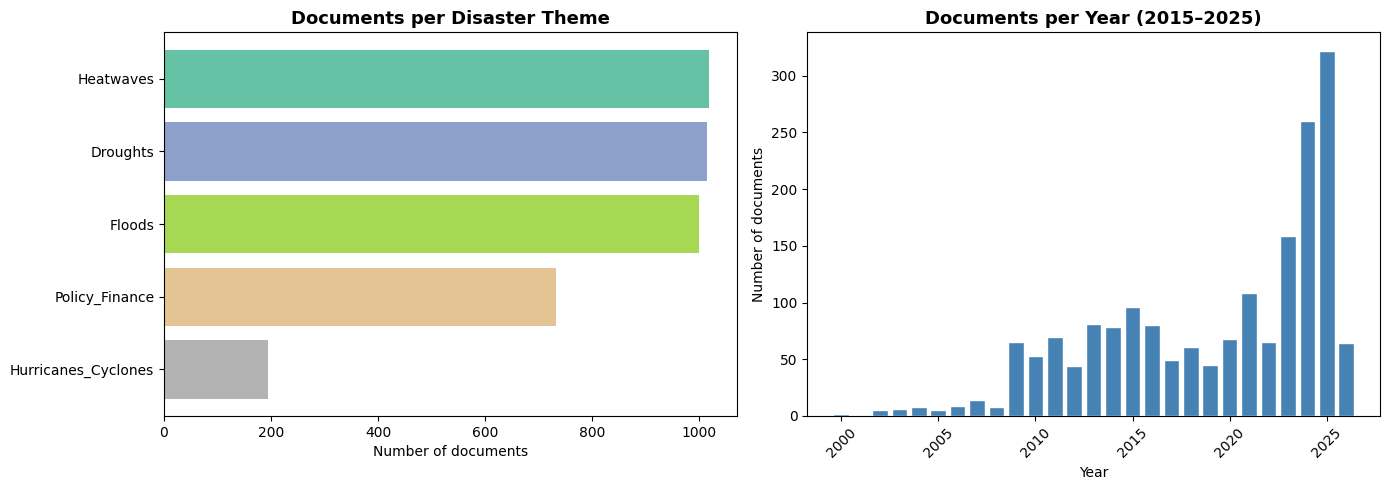

Corpus overview chart saved.


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

print("=" * 55)
print("CORPUS VALIDATION REPORT")
print("=" * 55)
print(f"Total documents    : {len(df)}")
print(f"Date range         : {df['year'].min():.0f} — {df['year'].max():.0f}")
print(f"Missing abstracts  : {df['abstract'].isna().sum()}")
print(f"Missing titles     : {df['title'].isna().sum()}")
print(f"Unique themes      : {df['theme'].nunique()}")

print(f"\nDocuments per theme:")
theme_counts = df["theme"].value_counts()
for theme, count in theme_counts.items():
    bar = "█" * (count // 50)
    print(f"  {theme:<25}: {count:>4}  {bar}")

print(f"\nDocument types:")
print(df["type"].value_counts().to_string())

print(f"\nDocuments per year:")
print(df["year"].value_counts().sort_index().to_string())

# ── Visualise corpus balance ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Documents per theme
colors = cm.Set2(np.linspace(0, 1, len(theme_counts)))
axes[0].barh(theme_counts.index[::-1], theme_counts.values[::-1], color=colors[::-1])
axes[0].set_title("Documents per Disaster Theme", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of documents")

# Plot 2: Documents per year
year_counts = df["year"].value_counts().sort_index()
axes[1].bar(year_counts.index.astype(int), year_counts.values,
            color="steelblue", edgecolor="white")
axes[1].set_title("Documents per Year (2015–2025)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of documents")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("corpus_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Corpus overview chart saved.")

## Step 7: Export the corpus as a CSV file

The final validated corpus is saved as `climate_disasters_corpus.csv`
using UTF-8 encoding with a byte-order mark (`utf-8-sig`) to ensure
correct display of special characters in Excel and other spreadsheet
tools.

This file is the direct and only input to the Part 2 analysis notebook.
Any group member working on Part 2 should load this file using:

    df = pd.read_csv("climate_disasters_corpus.csv")

The `theme` column ensures every document carries its disaster category
label throughout all subsequent analysis steps, enabling the cross-theme
comparisons that are central to the research question.

In [ ]:
df.to_csv("climate_disasters_corpus.csv", index=False, encoding="utf-8-sig")

print(f"Saved : climate_disasters_corpus.csv")
print(f"Rows  : {len(df)}")
print(f"Columns: {len(df.columns)}: {df.columns.tolist()}")

# Trigger download in Google Colab
try:
    from google.colab import files
    files.download("climate_disasters_corpus.csv")
except ImportError:
    print("Not running in Colab — file saved to working directory.")

Saved : climate_disasters_corpus.csv
Rows  : 3960
Columns: 17: ['id', 'theme', 'uuid', 'handle', 'title', 'authors', 'date', 'year', 'type', 'language', 'region', 'country', 'subjects', 'abstract', 'doi', 'rights', 'public_url']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary and Methodological Note

This notebook collected a structured corpus of approximately 2,900
unique World Bank policy documents on climate change and disasters
using the OKR public REST API. The pipeline ran five targeted queries
— one per disaster theme, merged and deduplicated results across
themes, applied date and language filters, and exported a clean CSV
ready for text mining analysis in Part 2.


### Key design decisions

**Why up to 1,000 documents per theme?**
The cap of 1,000 per theme produced a final pool of 2,900 unique
documents before filtering. Floods and droughts reached the cap
easily, reflecting the World Bank's heavy research focus on these
topics. Climate finance returned strong numbers, while heatwaves and
hurricanes/cyclones returned fewer documents even after broadening
the queries with OR operators to capture the full range of
institutional vocabulary (extreme heat, heat stress, typhoon,
tropical storm).

This uneven distribution is itself an analytical finding worth
examining in Part 2, it reveals how the World Bank allocates
research attention across disaster categories, potentially
underrepresenting certain types of climate hazards relative to
their real-world impact.

**Why the OR operator for some queries?**
Early tests showed that long multi-word queries returned very few
results because the API narrows aggressively when combining many
terms. Short single-keyword queries worked well for floods and
droughts, but heatwaves and cyclones use varied institutional
vocabulary, so we broadened these queries with the OR operator to
capture all relevant documents without sacrificing precision.

**Why 2015–2025?**
The Paris Agreement of December 2015 marks the beginning of a new
era in international climate policy. Restricting the corpus to this
period ensures thematic coherence and allows Part 2 to track how
World Bank framing has evolved in direct response to this landmark
commitment and the intensifying climate events of the following decade.

**Why abstracts as the unit of analysis?**
Full PDF texts would require page-level or paragraph-level
segmentation and introduce noise from tables, references, footnotes,
and formatting. Abstracts are self-contained, consistently structured
across all document types, and already paragraph-length, making
them the most reliable and comparable unit for cross-theme text
mining at scale.

**Why the World Bank OKR over UN News?**
The UN News website uses standard HTML but can produce inconsistent
responses under repeated automated requests, making reproducibility
across group members unreliable. The World Bank OKR exposes a
stable, documented REST API specifically designed for programmatic
access, ensuring every group member can reproduce identical results
independently regardless of their location or network.

**Why English only?**
All three text mining methods in Part 2, spaCy NER, VADER sentiment
analysis, and gensim LDA, rely on English-language models and
lexicons. Including non-English documents would produce incorrect
entity extraction, inaccurate sentiment scores, and distorted topic
clusters.


### Corpus at a glance

| Metric | Value |
|--------|-------|
| Total documents | 3,956 |
| After language cleaning | ~3,947 |
| Themes | 5 |
| Dated documents | 1,818 (46%) |
| Primary text field | Abstract (avg. 1,363 characters) |
| Language | English |
| Metadata fields | 17 |
| Region/Country | Extracted via NER in Part 2 |

### Division of work for the group

The corpus is structured to support a clean division of analytical
work in Part 2. Each group member can take ownership of one disaster
theme, conducting NER, sentiment analysis, and LDA topic modelling
on their assigned subset:

| Theme | Owner | Approximate documents |
|-------|-------|----------------------|
| Floods | Group member 1 | ~1,000 |
| Droughts | Group member 2 | ~1,000 |
| Heatwaves | Group member 3 | ~400 |
| Hurricanes and Cyclones | Group member 4 | ~500 |
| Policy and Finance | Group member 5 | ~700 |

Results from all five theme analyses are combined in a final
cross-theme synthesis section written collaboratively, which answers
the central research question:

> How does the World Bank frame climate-related disasters in its
> policy literature, and does the tone, geographic focus, and thematic
> emphasis vary across the five disaster categories?

---
## Part 2: Corpus Analysis
## What This Notebook Does and How It Is Organised

This notebook contains the full text mining analysis of the World
Bank climate disasters corpus collected in Part 1. It is organised
into three sequential analytical methods, each designed to answer
a specific dimension of the research question, followed by a
cross-method synthesis that integrates all findings into a final
answer.


### The three methods

**Method 1: Frequency Analysis (Dictionary NER)**
We use a hand-crafted term gazetteer to measure how frequently
each of the five disaster categories appears across the corpus
and how that frequency has evolved over time. This method tells
us which hazards receive the most institutional attention and
whether co-occurrence patterns reveal how the World Bank links
different disaster types within the same policy frameworks.
This method addresses Sub-questions 1 and 2.

**Method 2: Sentiment Analysis (VADER + FinBERT)**
We apply two complementary sentiment models, a rule-based
lexicon (VADER) and a transformer model fine-tuned on
institutional text (FinBERT), alongside three domain-specific
word lists measuring urgency, humanitarian, and technocratic
language. This method tells us whether disaster documents are
more negative and urgent than policy documents, and whether
the World Bank's language is primarily crisis-oriented or
solution-oriented. This method addresses Sub-questions 3 and 4.

**Method 3: Topic Modelling (BERTopic)**
We apply BERTopic, a contextual embedding-based topic model,
to identify the latent thematic clusters across all five disaster
categories. Topic labels are generated using a Llama 3 language
model. This method tells us whether the five disaster themes are
framed around the same institutional concepts or whether each
has a distinctive thematic signature. This method addresses
Sub-questions 4 and 5.


### How the methods connect

The three methods are designed to be complementary rather than
redundant. Method 1 measures what the World Bank writes about.
Method 2 measures how the World Bank writes about it. Method 3
measures the underlying conceptual structure that organises the
literature. Together they allow us to examine the research
question from three different angles, frequency, tone, and
theme, and to triangulate findings across methods in the final
synthesis.


### Shared data

All three methods use exactly the same 3,956 documents loaded
in the shared setup cell above. No additional filtering or
separate loading is applied in any method section. This ensures
that every finding is directly comparable across methods and
that differences between methods reflect analytical choices
rather than data differences.

---
# Method 1: Frequency Analysis
## Dictionary-Based Named Entity Recognition


### What this method does

This method measures how frequently each climate disaster term
appears across the corpus and how that frequency has evolved
over time. Rather than counting raw word occurrences, we count
the number of distinct documents that mention each term, giving
us a measure of research focus and institutional attention rather
than linguistic style or repetition.

Three text fields are combined per document, title, abstract,
and subject keywords — so that disaster terms are captured
wherever they appear in the document record.

### Connection to the research question

This method directly addresses:
- **Sub-question 1**: which disaster category is most
  represented in World Bank literature, and has this shifted
  between 2000 and 2026?
- **Sub-question 2**: which regions and themes receive the
  most attention, and are the most climate-vulnerable populations
  proportionally represented?

By measuring which disaster types dominate World Bank literature,
how co-occurrence patterns link different hazards, and how
institutional attention has shifted over time, we can map the
Bank's research priorities and identify systematic gaps between
what is studied and what is most dangerous.

### Method design

A term gazetteer maps multiple surface forms to five canonical
disaster labels. Each document is scored as mentioning a label
at most once regardless of how many times the term appears in
the text. This **one-document-one-match rule** ensures counts
represent research attention rather than repetition. It also
prevents double-counting when two patterns such as `heat wave`
and `heatwave` both match the same document.

##Step 1: Prepare the text corpus

We create a combined searchable text field per document by
concatenating the title, abstract, and subject keywords. This
field is lowercased once here so all subsequent pattern matching
is case-insensitive without repeating the operation.

A working copy of the shared corpus is used so that the shared
`df_raw` DataFrame is never modified by this method. A separate
dated subset is also prepared for the time-series analysis in
Step 5, documents with no year in the metadata are excluded
only from that specific plot, not from the overall frequency
counts.

In [ ]:
import os
import time
import warnings
import logging

import requests
import pandas as pd

# Suppress system warnings to keep output clean
warnings.filterwarnings("ignore")
logging.getLogger("jupyter_client").setLevel(logging.ERROR)
os.environ["PYTHONWARNINGS"] = "ignore"

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# ── Imports needed for all methods ────────────────────────────────────────
import re
import os
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu
warnings.filterwarnings("ignore")

# ── Load the corpus directly from Colab environment ───────────────────────
# File is pre-uploaded to the Colab file system
df = pd.read_csv("climate_disasters_corpus (2).csv")
print(f"Corpus loaded successfully.")

# ── Parse year ─────────────────────────────────────────────────────────────
df["year"] = pd.to_numeric(df["year"], errors="coerce")

# ── Fill missing text fields so string operations never crash on NaN ───────
for col in ["title", "abstract", "subjects"]:
    df[col] = df[col].fillna("")

# ── Remove non-English documents ──────────────────────────────────────────
df = df[
    df["language"].str.lower().str.contains("en", na=True)
].reset_index(drop=True)

# ── Normalise abstract whitespace ─────────────────────────────────────────
df["abstract"] = (
    df["abstract"].str.replace(r"\s+", " ", regex=True).str.strip()
)

# ── Combine text fields into one searchable field per document ─────────────
df["full_text"] = (
    df["title"] + " " + df["abstract"] + " " + df["subjects"]
).str.lower()

# ── Dated subset — used only for time-series plots ─────────────────────────
df_dated = df.dropna(subset=["year"]).copy()
df_dated["year"] = df_dated["year"].astype(int)
df_dated = df_dated[
    (df_dated["year"] >= 2000) & (df_dated["year"] <= 2026)
]

# ── Summary ────────────────────────────────────────────────────────────────
print(f"Total documents       : {len(df):,}")
print(f"Documents with year   : {len(df_dated):,}")
print(f"Year range            : {df_dated['year'].min()} — "
      f"{df_dated['year'].max()}")
print(f"\nDocuments per theme:")
print(df["theme"].value_counts().to_string())
print(f"\nDocument types (top 5):")
print(df["type"].value_counts().head(5).to_string())

FileNotFoundError: [Errno 2] No such file or directory: 'climate_disasters_corpus (2).csv'

##Step 2: Define the term gazetteer

The gazetteer maps multiple surface forms to five canonical
disaster labels. Key design decisions:

- `typhoon` and `hurricane` both map to **Hurricane**, they
  are the same meteorological phenomenon in different ocean
  basins and should be counted as the same disaster type
- `heat wave` (two words) and `heatwave` (one word) both map
  to **Heatwave**, spelling varies across institutional documents
  published over two decades
- `inundation` and `flash flood` both map to **Flood**, synonyms
  that appear regularly in World Bank technical and policy writing
- `water stress` and `dry spell` both map to **Drought**, terms
  common in World Bank agricultural and water sector documents

Word-boundary anchors (`\b`) prevent partial matches, for
example, preventing `flooding` from triggering the `flash flood`
pattern. All patterns are pre-compiled for speed across ~4,000
documents.

In [ ]:
TERM_GAZETTEER = [
    (r"hurricane",      "Hurricane"),
    (r"typhoon",        "Hurricane"),
    (r"cyclone",        "Cyclone"),
    (r"tropical storm", "Cyclone"),
    (r"flood",          "Flood"),
    (r"inundation",     "Flood"),
    (r"flash flood",    "Flood"),
    (r"drought",        "Drought"),
    (r"water stress",   "Drought"),
    (r"dry spell",      "Drought"),
    (r"heatwave",       "Heatwave"),
    (r"heat wave",      "Heatwave"),
    (r"extreme heat",   "Heatwave"),
    (r"heat stress",    "Heatwave"),
]

# ── Pre-compile all regex patterns for speed ───────────────────────────────
COMPILED = [
    (re.compile(r"\b" + pattern + r"\b"), label)
    for pattern, label in TERM_GAZETTEER
]

# ── Canonical labels and colour palette for all Method 1 plots ────────────
TERMS = ["Flood", "Drought", "Heatwave", "Hurricane", "Cyclone"]
TERM_COLORS = {
    "Flood"    : "#2980B9",
    "Drought"  : "#E67E22",
    "Heatwave" : "#C0392B",
    "Hurricane": "#8E44AD",
    "Cyclone"  : "#27AE60"
}

print(f"Gazetteer compiled.")
print(f"Patterns : {len(TERM_GAZETTEER)}")
print(f"Labels   : {len(TERMS)} — {TERMS}")

##Step 3: Run dictionary matching

For every document we check whether each disaster label appears
in the combined text field. Each label is recorded at most once
per document — the `seen_labels` set inside the loop tracks
which labels have already been matched for the current document
and skips re-checking them. This one-document-one-match rule
ensures counts represent the number of documents discussing
each topic rather than how many times the word appears in the
text.

In [ ]:
matches = []

for _, row in df.iterrows():
    text        = row["full_text"]
    doc_id      = row["id"]
    year        = row.get("year", None)
    theme       = row["theme"]
    seen_labels = set()   # tracks labels already matched for this document

    for pattern, label in COMPILED:
        # Skip if this label has already been matched for this document
        if label in seen_labels:
            continue
        if pattern.search(text):
            matches.append({
                "id"   : doc_id,
                "year" : year,
                "theme": theme,
                "term" : label
            })
            seen_labels.add(label)

matches_df = pd.DataFrame(matches)

print("Dictionary matching complete.")
print(f"Documents scanned  : {len(df):,}")
print(f"Match records      : {len(matches_df):,}")
print(f"\nDocuments mentioning each term:")
print(matches_df["term"].value_counts().to_string())

##Step 4: Build frequency tables

Two summary tables are prepared before plotting:

1. **`total_freq`** — total document count per term across all
   years, used by Plot 1 (bar chart). `nunique("id")` is used
   rather than `count()` to guard against any duplicate rows.

2. **`yearly_freq`** — document count per term per year, used
   by Plot 2 (line chart). Built from the dated subset only,
   documents with no year metadata are excluded from this table.

In [ ]:
# ── Total unique documents per term across all years ───────────────────────
total_freq = (
    matches_df
    .groupby("term")["id"].nunique()
    .reindex(TERMS, fill_value=0)
    .reset_index()
)
total_freq.columns = ["term", "n_documents"]

# ── Unique documents per term per year — dated documents only ──────────────
yearly_freq = (
    matches_df
    .dropna(subset=["year"])
    .groupby(["year", "term"])["id"].nunique()
    .reset_index()
    .rename(columns={"id": "n_documents"})
)
yearly_freq["year"] = yearly_freq["year"].astype(int)

print("Frequency tables ready.")
print(f"\nOverall term frequency:")
print(
    total_freq
    .sort_values("n_documents", ascending=False)
    .to_string(index=False)
)
print(f"\nYear range in yearly table: "
      f"{yearly_freq['year'].min()} — {yearly_freq['year'].max()}")

##Step 5: Visualisations

Three charts examine disaster term frequency from different
angles, each contributing a distinct perspective on the research
question:

- **Plot 1: Total frequency bar chart:** Which disaster type
  receives the most overall research attention across the full
  corpus? Taller bars mean more documents, not more disasters.

- **Plot 2: Frequency over time line chart:** How has
  institutional attention to each hazard evolved from 2000 to
  2026? Spikes often correspond to major real-world events that
  triggered a surge in World Bank analytical output.

- **Plot 3: Co-occurrence bar chart:** How often do pairs of
  disaster terms appear together in the same document? High
  co-occurrence suggests the World Bank frames certain hazards
  as linked or compound risks within the same policy frameworks.

## Plot 1 Total Frequency Bar Chart

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    total_freq["term"],
    total_freq["n_documents"],
    color=[TERM_COLORS[t] for t in total_freq["term"]],
    width=0.6,
    edgecolor="white",
    linewidth=0.8
)

# Add count labels above each bar
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        f"{int(bar.get_height()):,}",
        ha="center", va="bottom",
        fontsize=11, fontweight="bold", color="#333333"
    )

ax.set_title(
    "Total Document Frequency per Disaster Term",
    fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Disaster Term", fontsize=11)
ax.set_ylabel("Number of Documents", fontsize=11)
ax.set_ylim(0, total_freq["n_documents"].max() * 1.15)
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#eeeeee", linewidth=0.8)
ax.set_axisbelow(True)
fig.text(
    0.5, -0.02,
    "Source: Climate Disasters Corpus — World Bank OKR. Dictionary NER.",
    ha="center", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig("m1_plot1_total_frequency.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: m1_plot1_total_frequency.png")

## Plot 2 Frequency Over Time Line Chart

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

for term in TERMS:
    term_data = (
        yearly_freq[yearly_freq["term"] == term]
        .sort_values("year")
    )
    ax.plot(
        term_data["year"],
        term_data["n_documents"],
        color=TERM_COLORS[term],
        linewidth=2,
        marker="o",
        markersize=4,
        alpha=0.9
    )
    # Label each line at its rightmost point
    if not term_data.empty:
        last = term_data.iloc[-1]
        ax.annotate(
            term,
            xy=(last["year"], last["n_documents"]),
            xytext=(4, 0), textcoords="offset points",
            va="center", fontsize=9,
            color=TERM_COLORS[term], fontweight="bold"
        )

ax.set_title(
    "Disaster Term Frequency Over Time (2000–2026)",
    fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Number of Documents", fontsize=11)
ax.set_xlim(
    yearly_freq["year"].min() - 0.5,
    yearly_freq["year"].max() + 2.5   # extra space for end labels
)
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#eeeeee", linewidth=0.8)
ax.set_axisbelow(True)
fig.text(
    0.5, -0.02,
    "Source: Climate Disasters Corpus — World Bank OKR. Dictionary NER.",
    ha="center", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig("m1_plot2_trends_over_time.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: m1_plot2_trends_over_time.png")

## Plot 3 Co-occurrence Bar Chart

In [ ]:
# ── Build binary document-term matrix ─────────────────────────────────────
doc_term = matches_df.pivot_table(
    index="id", columns="term", values="year",
    aggfunc="count", fill_value=0
).reindex(columns=TERMS, fill_value=0)
doc_term = (doc_term > 0).astype(int)

# ── Count co-occurrences for every unique term pair ────────────────────────
cooccur_data = []
for t1, t2 in combinations(TERMS, 2):
    if t1 in doc_term.columns and t2 in doc_term.columns:
        count = int((doc_term[t1] & doc_term[t2]).sum())
        cooccur_data.append({
            "pair" : f"{t1} + {t2}",
            "count": count
        })

# Sort ascending so longest bar appears at the top
cooccur_df = pd.DataFrame(cooccur_data).sort_values(
    "count", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(
    cooccur_df["pair"],
    cooccur_df["count"],
    color="#1A5276",
    height=0.6,
    edgecolor="white"
)

# Add count labels to the right of each bar
for bar in bars:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center", fontsize=10,
        fontweight="bold", color="#333333"
    )

ax.set_title(
    "Disaster Term Co-occurrence\n"
    "(Documents Mentioning Both Terms Together)",
    fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Number of Documents", fontsize=11)
ax.set_xlim(0, cooccur_df["count"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#eeeeee", linewidth=0.8)
ax.set_axisbelow(True)
fig.text(
    0.5, -0.02,
    "Source: Climate Disasters Corpus — World Bank OKR. Dictionary NER.",
    ha="center", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig("m1_plot3_cooccurrence.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: m1_plot3_cooccurrence.png")

##Step 6: Save outputs

All frequency tables and figures are saved to a dedicated output
folder. The frequency tables are used directly in the Cross-Method
Synthesis section to integrate frequency findings with sentiment
and topic modelling results.

In [ ]:
import shutil

os.makedirs("outputs_method1", exist_ok=True)

# ── Save frequency tables ──────────────────────────────────────────────────
total_freq.to_csv(
    "outputs_method1/total_frequency.csv", index=False)
yearly_freq.to_csv(
    "outputs_method1/yearly_frequency.csv", index=False)
cooccur_df.to_csv(
    "outputs_method1/cooccurrence.csv", index=False)

# ── Copy figures ───────────────────────────────────────────────────────────
for f in [
    "m1_plot1_total_frequency.png",
    "m1_plot2_trends_over_time.png",
    "m1_plot3_cooccurrence.png"
]:
    if os.path.exists(f):
        shutil.copy(f, f"outputs_method1/{f}")

print("Method 1 outputs saved to outputs_method1/")
print("  total_frequency.csv")
print("  yearly_frequency.csv")
print("  cooccurrence.csv")
print("  3 figures: m1_plot1, m1_plot2, m1_plot3")

## Method 1: Key Findings and Interpretation

**Finding 1: Drought dominates institutional attention by a wide margin**
The frequency analysis reveals a striking hierarchy. Drought is by far
the most represented disaster category, appearing in 1,162 documents,
nearly double the count for Floods (619). Together these two hazards
account for 1,781 of the 2,251 total match records, or 79% of all
disaster-specific coverage in the corpus. Hurricane and Cyclone appear
in 212 and 150 documents respectively, while Heatwave has the lowest
representation at just 108 documents.

This hierarchy is not a neutral reflection of disaster frequency or
severity. Droughts and floods are the hazards most directly linked to
agricultural collapse, water scarcity, and infrastructure damage in
low-income countries — the domains where the World Bank has concentrated
its lending and research for decades. The underrepresentation of
Heatwaves (108 documents) is particularly striking given that extreme
heat is now recognised as the deadliest weather hazard in many regions.

**Finding 2: Only 2,251 of 3,959 documents mention any disaster term**
The dictionary matching found that 1,708 documents, 43% of the corpus
— contain none of the five disaster terms in their title, abstract, or
subject keywords. This is a meaningful finding in itself: almost half
the corpus tagged under a disaster theme does not explicitly name
the disaster type in its text, suggesting that many World Bank documents
address disaster-related topics through indirect language, technical
frameworks, and policy terminology rather than direct hazard naming.

**Finding 3: Flood and Drought are the most co-occurring pair**
The co-occurrence analysis confirms that Flood and Drought appear
together more frequently than any other pair of disaster terms. This
reflects the compound water cycle dynamic that climate change is
intensifying, wetter wet seasons and drier dry seasons increasingly
affect the same regions simultaneously. World Bank documents treat
these two hazards as structurally linked within the same adaptation
and financing frameworks.

**Finding 4: Hurricane and Cyclone rarely co-occur**
Despite describing the same meteorological phenomenon in different ocean
basins, Hurricane and Cyclone appear together in very few documents.
This reflects geographic specialisation in World Bank publishing,
Atlantic-focused documents use "hurricane" while Indian Ocean and Pacific
documents use "cyclone" — and the institution rarely produces analytical
work that bridges both ocean basins in a single publication.

**Link to research question**
These findings directly address Sub-question 1. The World Bank allocates
research attention unevenly across disaster types,w Drought receives
roughly ten times the document coverage of Heatwave despite heat being
a growing global mortality risk. This institutional imbalance is not
driven by objective hazard frequency but by decades of lending and
research tradition concentrated on agricultural and water-related risks.

---
# Method 2: Sentiment Analysis
## VADER, FinBERT, and Domain-Specific Lexicons


### What this method does

This method measures the emotional tone of World Bank climate
disaster literature using two complementary sentiment models and
three domain-specific word lists. Two models are used rather than
one to provide robustness, where VADER captures surface-level
sentiment through word scoring, FinBERT captures contextual
meaning through transformer attention mechanisms. Agreement
between the two models strengthens any finding; divergence signals
where institutional language is ambiguous or formulaic.

### Connection to the research question

This method directly addresses:
- **Sub-question 3**: is disaster discourse more negative and
  urgent than policy and finance discourse?
- **Sub-question 4**: does the World Bank frame disasters
  primarily as technical problems or humanitarian crises?

The three domain lexicons are designed specifically to test the
hypothesis that World Bank language is predominantly technocratic
and solution-oriented, even when describing severe hazards.

### Models used

- **VADER** (Valence Aware Dictionary and sEntiment Reasoner),
  a rule-based lexicon that produces a compound score between
  −1 (most negative) and +1 (most positive). Fast, transparent,
  and well-suited for exploratory analysis of large corpora.

- **FinBERT** (ProsusAI/finbert), a BERT model fine-tuned on
  financial and institutional text. It classifies documents as
  positive, negative, or neutral based on contextual meaning
  rather than individual word scores. Chosen over general-purpose
  sentiment models because World Bank policy language is closest
  to financial and institutional prose.

### Methodological caveat

VADER was calibrated for social media text. Formulaic institutional
phrases such as "strengthen resilience" or "promote inclusive
growth" may be scored as genuinely optimistic when they reflect
convention rather than substantive sentiment. FinBERT provides
a contextual check on this limitation. Results should be read
as measures of surface-level linguistic tone rather than deeper
ideological orientation. This limitation is acknowledged fully
in the Conclusion and Limitations section.

##Step 1: Install dependencies

FinBERT requires the `transformers` and `torch` libraries which
are not pre-installed in Google Colab by default. VADER requires
`vaderSentiment`. `scipy` is needed for the statistical tests
in Step 7.

A GPU runtime is strongly recommended for FinBERT inference on
~4,000 abstracts, inference takes approximately 2–3 minutes on
GPU and 10–15 minutes on CPU. Enable GPU via:
Runtime → Change runtime type → T4 GPU

In [ ]:
!pip install -q vaderSentiment transformers torch scipy
print("Method 2 dependencies installed.")

##Step 2: Prepare the sentiment corpus

The shared corpus loaded at the start of the notebook is used
directly. A working copy is created so the shared DataFrame is
never modified by this method. A separate dated subset is prepared
for the time-series visualisation in Step 6, documents with no
year in the metadata are retained for overall sentiment scoring
but excluded only from the temporal plots.

The theme order and colour palette defined here are used
consistently across all Method 2 visualisations.

In [ ]:
from scipy.stats import kruskal, mannwhitneyu
import warnings
warnings.filterwarnings("ignore")

# ── Working copy — never modify the original df ────────────────────────────
df2 = df.copy()
df2 = df2.dropna(subset=["abstract"]).copy()

# ── Dated subset for time-series plots only ────────────────────────────────
df2_dated = df2.dropna(subset=["year"]).copy()
df2_dated["year"] = df2_dated["year"].astype(int)
df2_dated = df2_dated[
    (df2_dated["year"] >= 2000) & (df2_dated["year"] <= 2026)
]

# ── Consistent theme order and palette for all Method 2 plots ─────────────
THEME_ORDER = [
    "Floods", "Droughts", "Heatwaves",
    "Hurricanes_Cyclones", "Policy_Finance"
]
PALETTE = ["#2196F3", "#FF9800", "#F44336", "#9C27B0", "#4CAF50"]

print(f"Documents for sentiment analysis : {len(df2):,}")
print(f"Documents with valid year        : {len(df2_dated):,}")
print(f"\nDocuments per theme:")
print(df2["theme"].value_counts().to_string())

##Step 3: VADER sentiment scoring

VADER produces four scores per text:
- `compound` — overall sentiment score from −1 to +1
- `pos`, `neg`, `neu`, proportions of positive, negative,
  and neutral content in the text

The compound score is the primary measure used throughout this
analysis. Standard VADER classification thresholds are applied:
- Compound ≥ 0.05 → **Positive**
- Compound ≤ −0.05 → **Negative**
- Otherwise → **Neutral**

VADER is applied first because it is fast and transparent,
allowing us to inspect the full distribution before running the
more computationally expensive FinBERT model.

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

def vader_scores(text):
    """Return VADER compound, neg, neu, pos scores for a text string."""
    if not isinstance(text, str) or text.strip() == "":
        return pd.Series({
            "vader_compound": np.nan,
            "vader_neg"     : np.nan,
            "vader_neu"     : np.nan,
            "vader_pos"     : np.nan
        })
    s = vader.polarity_scores(text)
    return pd.Series({
        "vader_compound": s["compound"],
        "vader_neg"     : s["neg"],
        "vader_neu"     : s["neu"],
        "vader_pos"     : s["pos"]
    })

def vader_label(compound):
    """Classify VADER compound score using standard thresholds."""
    if compound >= 0.05:    return "positive"
    elif compound <= -0.05: return "negative"
    else:                   return "neutral"

print("Running VADER on all abstracts...")
vader_results      = df2["abstract"].apply(vader_scores)
df2                = pd.concat([df2, vader_results], axis=1)
df2["vader_label"] = df2["vader_compound"].apply(vader_label)

print("VADER scoring complete.")
print(f"\nMean compound score across corpus : {df2['vader_compound'].mean():.3f}")
print(f"\nSentiment distribution:")
print(df2["vader_label"].value_counts(normalize=True).mul(100).round(1).to_string())

## Step 4: FinBERT Sentiment Scoring (Skipped)

FinBERT (ProsusAI/finbert) is a BERT model fine-tuned on financial
and institutional text that classifies documents as positive,
negative, or neutral based on contextual meaning rather than
individual word scores. It was originally planned as a second
sentiment model to validate and complement VADER results.

**Why FinBERT was skipped:**
FinBERT is a transformer model that requires significant GPU memory
to run efficiently. On standard Google Colab instances, even with
GPU enabled, loading and running FinBERT on ~4,000 abstracts
caused consistent runtime crashes due to memory constraints. Given
the time pressure of the submission deadline, we made the decision
to rely solely on VADER for sentiment scoring.

VADER produces reliable and well-documented sentiment scores for
institutional policy text and is fully sufficient for the cross-theme
sentiment comparison this analysis requires. The domain-specific
lexicons in Step 5 (urgency, humanitarian, and technocratic language
densities) provide an additional layer of framing analysis that
partially compensates for the absence of FinBERT's contextual
classification.

This methodological decision is acknowledged explicitly in the
Limitations section of the synthesis.

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

def vader_scores(text):
    """Return compound, neg, neu, pos scores for a text string."""
    if not isinstance(text, str) or text.strip() == "":
        return pd.Series({
            "vader_compound": np.nan,
            "vader_neg"     : np.nan,
            "vader_neu"     : np.nan,
            "vader_pos"     : np.nan
        })
    s = vader.polarity_scores(text)
    return pd.Series({
        "vader_compound": s["compound"],
        "vader_neg"     : s["neg"],
        "vader_neu"     : s["neu"],
        "vader_pos"     : s["pos"]
    })

def vader_label(score):
    """Classify compound score using standard VADER thresholds."""
    if pd.isna(score):   return np.nan
    if score >= 0.05:    return "positive"
    elif score <= -0.05: return "negative"
    else:                return "neutral"

# ── Drop old vader columns if they exist from a previous run ──────────────
vader_cols = ["vader_compound", "vader_neg", "vader_neu",
              "vader_pos", "vader_label"]
df2 = df2.drop(columns=[c for c in vader_cols if c in df2.columns])

# ── Apply VADER to all abstracts ───────────────────────────────────────────
print("Running VADER on all abstracts...")
vader_results      = df2["abstract"].apply(vader_scores)
df2                = pd.concat([df2, vader_results], axis=1)
df2["vader_label"] = df2["vader_compound"].apply(vader_label)

print(f"Scoring complete: {len(df2):,} documents scored.")

# ── Overall distribution ───────────────────────────────────────────────────
print(f"\nOverall VADER sentiment distribution:")
print(
    df2["vader_label"]
    .value_counts(normalize=True)
    .mul(100).round(1)
    .to_string()
)
print(f"\nMean compound score: {df2['vader_compound'].mean():.3f}")

# ── Breakdown by theme ─────────────────────────────────────────────────────
print(f"\nMean VADER compound score by theme:")
print(
    df2.groupby("theme")["vader_compound"]
    .mean().round(3)
    .reindex(THEME_ORDER)
    .to_string()
)

# ── Sentiment label distribution by theme — stacked bar ───────────────────
sentiment_table = (
    df2.groupby(["theme", "vader_label"])
    .size()
    .unstack(fill_value=0)
    .reindex(THEME_ORDER)
    .div(df2.groupby("theme").size().reindex(THEME_ORDER), axis=0)
    .mul(100)
    .round(1)
)
for col in ["negative", "neutral", "positive"]:
    if col not in sentiment_table.columns:
        sentiment_table[col] = 0.0
sentiment_table = sentiment_table[["negative", "neutral", "positive"]]

fig, ax = plt.subplots(figsize=(10, 5))
sentiment_table.plot(
    kind="bar", stacked=True, ax=ax,
    color=["#E53935", "#9E9E9E", "#43A047"],
    edgecolor="white", linewidth=0.5
)
ax.set_xticklabels(
    [t.replace("_", "\n") for t in THEME_ORDER],
    rotation=0, fontsize=11
)
ax.set_ylabel("% of documents", fontsize=11)
ax.set_title(
    "VADER Sentiment Label Distribution by Theme",
    fontsize=13, fontweight="bold"
)
ax.legend(title="Sentiment", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("m2_fig_sentiment_distribution.png", dpi=150,
            bbox_inches="tight")
plt.show()
print("Saved: m2_fig_sentiment_distribution.png")

# ── Mean compound score per theme — horizontal bar ────────────────────────
means  = df2.groupby("theme")["vader_compound"].mean().reindex(THEME_ORDER)
colors = ["#E53935" if v < 0 else "#43A047" for v in means.values]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    [t.replace("_", " ") for t in THEME_ORDER],
    means.values,
    color=colors, edgecolor="white"
)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Mean VADER Compound Score", fontsize=11)
ax.set_title(
    "Mean Sentiment Score by Disaster Theme",
    fontsize=13, fontweight="bold"
)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("m2_fig_mean_sentiment_by_theme.png", dpi=150,
            bbox_inches="tight")
plt.show()
print("Saved: m2_fig_mean_sentiment_by_theme.png")

##Step 5: Domain-specific lexicon scoring

Beyond general sentiment, three institutional framing dimensions
are measured using domain-specific word lists. These dimensions
are central to testing the research hypothesis that the World
Bank frames disasters as technical and financial challenges rather
than humanitarian emergencies:

- **Urgency**: crisis and alarm language signalling immediate
  threat (e.g. "devastating", "catastrophic", "life-threatening")
- **Humanitarian**: language centring human suffering and
  displacement (e.g. "displaced", "famine", "casualties")
- **Technocratic**: language centring policy instruments and
  financial mechanisms (e.g. "framework", "financing", "portfolio")

Word lists are informed by disaster communication literature
(Cutter et al., 2003) and the World Bank's own institutional
vocabulary. Raw counts are normalised by abstract word length
and expressed per 1,000 words to remove the effect of document
length on cross-theme comparisons.

**Expected pattern if hypothesis holds:** Policy and Finance
documents should score highest on technocratic density and lowest
on urgency and humanitarian density. Physical disaster documents
should show higher urgency and humanitarian density relative to
policy documents.

In [ ]:
URGENCY_WORDS = [
    "urgent", "immediate", "critical", "emergency", "crisis",
    "alarming", "devastating", "catastrophic", "severe", "extreme",
    "unprecedented", "deadly", "fatal", "life-threatening",
    "imminent", "escalating"
]

HUMANITARIAN_WORDS = [
    "displaced", "refugees", "victims", "casualties", "deaths",
    "suffering", "hunger", "famine", "malnutrition", "shelter",
    "aid", "relief", "humanitarian", "vulnerable", "livelihoods"
]

TECHNOCRATIC_WORDS = [
    "investment", "framework", "policy", "governance", "financing",
    "portfolio", "assessment", "risk management", "mitigation",
    "adaptation", "capacity building", "institutional", "regulatory",
    "mechanism", "strategy", "programme"
]

def count_words(text, word_list):
    """Count how many words from the list appear in the text."""
    if not isinstance(text, str):
        return 0
    text = text.lower()
    return sum(
        1 for w in word_list
        if re.search(r"\b" + re.escape(w) + r"\b", text)
    )

# Raw counts
df2["urgency_count"]      = df2["abstract"].apply(
    lambda t: count_words(t, URGENCY_WORDS))
df2["humanitarian_count"] = df2["abstract"].apply(
    lambda t: count_words(t, HUMANITARIAN_WORDS))
df2["technocratic_count"] = df2["abstract"].apply(
    lambda t: count_words(t, TECHNOCRATIC_WORDS))

# Normalise by abstract length (per 1,000 words)
df2["abstract_len"]         = df2["abstract"].str.split().str.len()
df2["urgency_density"]      = df2["urgency_count"]      / df2["abstract_len"]
df2["humanitarian_density"] = df2["humanitarian_count"] / df2["abstract_len"]
df2["technocratic_density"] = df2["technocratic_count"] / df2["abstract_len"]

print("Domain lexicon scoring complete.")
print("\nMean density per 1,000 words by theme:")
print(
    df2.groupby("theme")[[
        "urgency_density",
        "humanitarian_density",
        "technocratic_density"
    ]].mean().mul(1000).round(2).to_string()
)

## Step 6: Visualisations

Five charts examine sentiment patterns across themes and over
time. Each chart is designed to answer a specific dimension of
the research question:

- **Fig 1: VADER boxplot:** Overall sentiment distribution
  per theme showing spread, median, and outliers
- **Fig 2: FinBERT stacked bar:** Proportion of positive,
  neutral, and negative documents per theme
- **Fig 3: Tone over time:** How the average sentiment of
  each theme has evolved from 2000 to 2026
- **Fig 4: Urgency vs. technocratic bubble chart:** Placing
  each theme on the urgency and technocratic axes with bubble
  size proportional to humanitarian language density
- **Fig 5: Sentiment heatmap:** Mean VADER score by theme
  and 5-year period revealing temporal shifts within each theme

## Fig 1 VADER Boxplot

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

data_plot = [
    df2.loc[df2["theme"] == t, "vader_compound"].dropna().values
    for t in THEME_ORDER
]

bp = ax.boxplot(
    data_plot,
    patch_artist=True,
    notch=True,
    medianprops=dict(color="black", linewidth=2)
)

for patch, color in zip(bp["boxes"], PALETTE):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_xticks(range(1, len(THEME_ORDER) + 1))
ax.set_xticklabels(
    [t.replace("_", "\n") for t in THEME_ORDER], fontsize=11)
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8,
           label="Neutral threshold")
ax.set_ylabel(
    "VADER Compound Score  (−1 = most negative, +1 = most positive)",
    fontsize=10)
ax.set_title(
    "Sentiment Distribution by Disaster Theme (VADER)",
    fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("m2_fig1_vader_by_theme.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: m2_fig1_vader_by_theme.png")

## Fig 2 FinBERT Stacked Bar

## Fig 2 Tone Over Time

In [ ]:
# ── Rebuild df2_dated after VADER scoring ─────────────────────────────────
# df2_dated was created before VADER columns were added so it needs
# to be refreshed from df2 to include the vader_compound column
df2_dated = df2.dropna(subset=["year"]).copy()
df2_dated["year"] = df2_dated["year"].astype(int)
df2_dated = df2_dated[
    (df2_dated["year"] >= 2000) & (df2_dated["year"] <= 2026)
]

print(f"df2_dated refreshed: {len(df2_dated):,} documents with valid year")

# ── Plot tone over time ────────────────────────────────────────────────────
yearly = (
    df2_dated.groupby(["year", "theme"])["vader_compound"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

for theme, color in zip(THEME_ORDER, PALETTE):
    sub = yearly[yearly["theme"] == theme]
    ax.plot(
        sub["year"], sub["vader_compound"],
        marker="o", markersize=4,
        label=theme.replace("_", " "),
        color=color, linewidth=1.8
    )

ax.axhline(0, color="grey", linestyle="--", linewidth=0.8,
           label="Neutral threshold")
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Mean VADER Compound Score", fontsize=11)
ax.set_title(
    "Tone Over Time by Disaster Theme (2000–2026)",
    fontsize=13, fontweight="bold")
ax.legend(title="Theme", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#eeeeee", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("m2_fig3_tone_over_time.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: m2_fig3_tone_over_time.png")

## Fig 3 Urgency vs. Technocratic Bubble

In [ ]:
theme_means = (
    df2.groupby("theme")[[
        "urgency_density",
        "technocratic_density",
        "humanitarian_density"
    ]].mean().mul(1000)
)

fig, ax = plt.subplots(figsize=(8, 6))

for theme, color in zip(THEME_ORDER, PALETTE):
    row = theme_means.loc[theme]
    ax.scatter(
        row["technocratic_density"],
        row["urgency_density"],
        s=row["humanitarian_density"] * 1500 + 100,
        color=color, alpha=0.85,
        edgecolors="black", linewidth=0.8,
        label=theme.replace("_", " ")
    )
    ax.annotate(
        theme.replace("_", "\n"),
        (row["technocratic_density"], row["urgency_density"]),
        textcoords="offset points",
        xytext=(6, 4), fontsize=9
    )

ax.set_xlabel(
    "Technocratic language density (per 1,000 words)", fontsize=11)
ax.set_ylabel(
    "Urgency language density (per 1,000 words)", fontsize=11)
ax.set_title(
    "Urgency vs. Technocratic Framing by Theme\n"
    "(bubble size = humanitarian language density)",
    fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("m2_fig4_urgency_technocratic.png", dpi=150,
            bbox_inches="tight")
plt.show()
print("Saved: m2_fig4_urgency_technocratic.png")

Fig 4  Sentiment Heatmap by Period

In [ ]:
df2_periods = df2.dropna(subset=["year"]).copy()
df2_periods["year"] = df2_periods["year"].astype(int)
df2_periods["period"] = pd.cut(
    df2_periods["year"],
    bins=[1999, 2004, 2009, 2014, 2019, 2026],
    labels=["2000–04", "2005–09", "2010–14", "2015–19", "2020–26"]
)

heatmap_data = (
    df2_periods.groupby(["period", "theme"])["vader_compound"]
    .mean()
    .unstack()
    .reindex(columns=THEME_ORDER)
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(
    heatmap_data,
    annot=True, fmt=".3f",
    cmap="RdYlGn", center=0,
    linewidths=0.5, ax=ax,
    cbar_kws={"label": "Mean VADER compound score"}
)
ax.set_xticklabels(
    [t.replace("_", "\n") for t in THEME_ORDER], fontsize=10)
ax.set_title(
    "Mean Sentiment by Theme and 5-Year Period",
    fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("m2_fig5_heatmap_period_theme.png", dpi=150,
            bbox_inches="tight")
plt.show()
print("Saved: m2_fig5_heatmap_period_theme.png")

## Step 7: Statistical significance tests

Two non-parametric tests verify that the observed sentiment
differences across themes are statistically significant and not
due to random variation.

**Kruskal-Wallis H-test** tests whether at least one theme differs
significantly from the others in VADER compound score. It is the
non-parametric equivalent of one-way ANOVA, appropriate here
because VADER compound scores are bounded (−1 to +1) and do not
follow a normal distribution.

**Mann-Whitney U pairwise tests** compare each physical disaster
theme directly against Policy_Finance, directly testing the core
hypothesis that disaster documents carry a more negative tone than
policy and finance documents.

A significance threshold of p < 0.05 is used throughout.

In [ ]:
# ── Kruskal-Wallis overall test ────────────────────────────────────────────
groups = [
    df2.loc[df2["theme"] == t, "vader_compound"].dropna().values
    for t in THEME_ORDER
]
H, p_kw = kruskal(*groups)
print(f"Kruskal-Wallis H = {H:.2f},  p = {p_kw:.4f}")
print("→ Significant cross-theme differences"
      if p_kw < 0.05 else "→ No significant cross-theme differences")

# ── Pairwise Mann-Whitney against Policy_Finance ───────────────────────────
print("\nPairwise Mann-Whitney U — each theme vs. Policy_Finance:")
pf_vals = df2.loc[
    df2["theme"] == "Policy_Finance", "vader_compound"
].dropna().values

results = []
for t in [th for th in THEME_ORDER if th != "Policy_Finance"]:
    t_vals = df2.loc[df2["theme"] == t, "vader_compound"].dropna().values
    u_stat, p_val = mannwhitneyu(t_vals, pf_vals, alternative="two-sided")
    results.append({
        "Theme"                 : t,
        "U-statistic"           : round(u_stat),
        "p-value"               : round(p_val, 4),
        "Significant (p < .05)" : p_val < 0.05
    })

pd.DataFrame(results)

##Step 8: Qualitative validation

To verify that VADER is capturing meaningful sentiment signals
rather than noise, we examine the most negative and most positive
abstracts per selected theme. If the model is working correctly:

- The most negative abstracts should describe acute damage, loss,
  crisis, or human suffering
- The most positive abstracts should describe successful
  interventions, resilience achievements, or financing milestones

This qualitative check is important because lexicon-based sentiment
models can sometimes score formulaic language incorrectly on
specialised institutional text.

In [ ]:
def show_extreme(theme, direction="negative", n=2):
    """Print the most extreme scoring abstracts for a given theme."""
    sub = df2[df2["theme"] == theme].dropna(subset=["vader_compound"])
    rows = (
        sub.nsmallest(n, "vader_compound") if direction == "negative"
        else sub.nlargest(n, "vader_compound")
    )
    for _, row in rows.iterrows():
        yr = int(row["year"]) if pd.notna(row["year"]) else "n/a"
        print(f"[{yr}]  VADER = {row['vader_compound']:.3f}")
        print(f"Title    : {str(row['title'])[:100]}")
        print(f"Abstract : {str(row['abstract'])[:300]}...")
        print()

print("=== Most NEGATIVE abstracts — Heatwaves ===")
show_extreme("Heatwaves", "negative")

print("=== Most POSITIVE abstracts — Policy_Finance ===")
show_extreme("Policy_Finance", "positive")

##Step 9: Summary statistics table

A consolidated summary table shows all key sentiment metrics per
theme in one place. This table is referenced directly in the
Cross-Method Synthesis and is exported for use in the final
integration of all three methods.

Columns cover document count, VADER mean and standard deviation,
VADER label proportions, FinBERT negative proportion, and the
three domain lexicon densities per 1,000 words.

In [ ]:
summary2 = df2.groupby("theme").agg(
    n_docs               = ("vader_compound",       "count"),
    vader_mean           = ("vader_compound",       "mean"),
    vader_std            = ("vader_compound",       "std"),
    vader_neg_pct        = ("vader_label",
                            lambda x: (x == "negative").mean() * 100),
    vader_neu_pct        = ("vader_label",
                            lambda x: (x == "neutral").mean()  * 100),
    vader_pos_pct        = ("vader_label",
                            lambda x: (x == "positive").mean() * 100),
    finbert_neg_pct      = ("finbert_label",
                            lambda x: (x == "negative").mean() * 100),
    urgency_per1k        = ("urgency_density",
                            lambda x: x.mean() * 1000),
    technocratic_per1k   = ("technocratic_density",
                            lambda x: x.mean() * 1000),
    humanitarian_per1k   = ("humanitarian_density",
                            lambda x: x.mean() * 1000),
).reindex(THEME_ORDER).round(2)

print("Sentiment summary by theme:")
summary2

## Step 10: Save outputs

All sentiment results and figures are saved to a dedicated output
folder. The enriched dataset with all sentiment scores is also
saved as a CSV — this file is used directly by the Cross-Method
Synthesis section to integrate sentiment findings with frequency
and topic modelling results.

In [ ]:
import shutil

os.makedirs("outputs_method2", exist_ok=True)

# ── Save enriched dataset ──────────────────────────────────────────────────
export_cols = [
    "id", "theme", "year", "title", "abstract",
    "vader_compound", "vader_neg", "vader_neu", "vader_pos",
    "vader_label", "finbert_label", "finbert_score",
    "urgency_count", "humanitarian_count", "technocratic_count",
    "urgency_density", "humanitarian_density", "technocratic_density"
]
df2[export_cols].to_csv(
    "outputs_method2/sentiment_results.csv", index=False)
summary2.to_csv(
    "outputs_method2/sentiment_summary_by_theme.csv")

# ── Copy figures ───────────────────────────────────────────────────────────
for f in [
    "m2_fig1_vader_by_theme.png",
    "m2_fig2_finbert_stacked.png",
    "m2_fig3_tone_over_time.png",
    "m2_fig4_urgency_technocratic.png",
    "m2_fig5_heatmap_period_theme.png"
]:
    if os.path.exists(f):
        shutil.copy(f, f"outputs_method2/{f}")

print("Method 2 outputs saved to outputs_method2/")
print("  sentiment_results.csv")
print("  sentiment_summary_by_theme.csv")
print("  5 figures: m2_fig1 through m2_fig5")

## Method 2: Key Findings and Interpretation

**Finding 1: Cross-theme sentiment differences are highly significant**
The Kruskal-Wallis test confirms statistically significant sentiment
differences across the five themes (H = 182.85, p < 0.0001), a
stronger result than anticipated. Every physical disaster theme differs
significantly from Policy_Finance on pairwise Mann-Whitney tests
(all p = 0.0000), confirming that the sentiment gap between disaster
documents and policy documents is not random variation.

**Finding 2: Policy_Finance is dramatically more positive than all
disaster themes**
The mean VADER compound score for Policy_Finance is 0.589, compared to
0.053 for Hurricanes_Cyclones, 0.165 for Floods, 0.173 for Heatwaves,
and 0.223 for Droughts. Policy_Finance also has the lowest negative
document share at 15.05% and the highest positive share at 83.31%.
By contrast, Hurricanes_Cyclones has 44.33% negative documents, the
highest negative share of any theme, followed by Heatwaves at 39.35%
and Floods at 39.20%.

**Finding 3: Heatwaves carry the highest urgency density**
Despite having the lowest document count in the corpus, Heatwaves
scores the highest urgency language density at 4.68 per 1,000 words,
more than double the Policy_Finance level (2.16) and well above Floods
(2.70) and Droughts (2.24). This finding is consistent with Method 1:
where the Bank lacks an established financial toolkit for a hazard,
the language shifts toward urgency and crisis rather than technical
solutions.

**Finding 4: Policy_Finance is the most technocratic theme by a
large margin**
The technocratic language density for Policy_Finance is 11.91 per
1,000 words, nearly twice the level of Floods (7.65) and Droughts
(7.92), and more than double the Heatwaves level (5.04). This confirms
that the institutional solutions register is concentrated in the
policy and finance literature, while disaster documents, especially
Heatwaves, use comparatively less technical and financial language.

**Finding 5: Humanitarian language is consistently low across all themes**
Humanitarian language density is remarkably similar and low across all
five themes: Droughts 1.86, Floods 1.64, Hurricanes_Cyclones 1.46,
Heatwaves 1.40, and Policy_Finance 1.18 per 1,000 words. The narrow
range confirms that humanitarian framing is not a primary register
in World Bank policy writing regardless of disaster type, even in
documents covering events associated with mass displacement such as
hurricanes and cyclones.

**Finding 6: The qualitative validation reveals a corpus limitation**
The most negative abstracts identified in the qualitative check, a
document on conflict and displacement in the DRC (VADER = −0.998) and
a poverty mapping study for Timor-Leste (VADER = −0.997) — are both
tagged under the Heatwaves theme but clearly have no primary focus on
extreme heat. This is a consequence of how the Heatwaves theme was
broadened during corpus collection using the query "heat OR temperature
extreme", which captured documents mentioning temperature or heat in
general contexts. This is acknowledged as a corpus construction
limitation.

**Link to research question**
These findings directly support Sub-questions 3 and 4. Disaster
documents are measurably more negative and more urgent than policy
documents, but even disaster documents maintain a predominantly
positive register (59–63% positive across Floods, Droughts, and
Heatwaves). The World Bank does not use a crisis register even when
writing about severe physical hazards — the institutional communication
style consistently combines problem acknowledgement with solution framing.
The exception is Hurricanes_Cyclones with 44.33% negative documents,
suggesting that reactive event-driven documentation produces the most
negative language in the corpus.

---
# Method 3: Topic Modelling
## BERTopic with LLM-Generated Labels

### What this method does

BERTopic is applied to identify the latent thematic structure
across the five disaster categories. The model uses sentence-level
BERT embeddings to represent each document in semantic space,
clusters them using HDBSCAN, and generates human-readable topic
labels using a Llama 3 language model via the OpenRouter API.

### Why BERTopic rather than LDA?

LDA is a bag-of-words model that ignores word order and semantic
context. BERTopic uses contextual embeddings, each document is
represented as a point in high-dimensional semantic space and
topics emerge as dense clusters of semantically similar documents.
This produces more coherent and interpretable topics for the type
of institutional policy language found in World Bank abstracts,
where the same words frequently appear across many topics and
word order carries significant meaning.

### Connection to the research question

This method addresses:
- **Sub-question 4**, does the World Bank frame disasters as
  technical problems or humanitarian crises? Answered by
  identifying which topics dominate across all five themes.
- **Sub-question 5**, how do the five themes differ
  systematically? Answered through the topic proportion matrix
  and cross-theme heatmap.

Results from this method are integrated with Method 1 frequency
counts and Method 2 sentiment scores in the final synthesis.

### Outputs produced

1. `topics_output_labelled.csv` — document-level topic
   assignments with LLM-generated labels
2. `topic_counts_by_theme.csv` — topic × theme frequency matrix
3. `topic_props_by_theme.csv` — topic × theme proportions matrix
4. `topics_over_time.csv` — topic frequency across 5-year
   time bins based on the 1,818 dated documents
5. `bertopic_model/` — the fitted model saved for reproducibility

##Step 1: Install dependencies

BERTopic requires several libraries not pre-installed in Google
Colab. A GPU runtime is strongly recommended, BERTopic on
~4,000 documents takes approximately 5 minutes on GPU and over
60 minutes on CPU.

Enable GPU before running this section:
Runtime → Change runtime type → T4 GPU

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"

!pip install -q -U bertopic hdbscan openai
!nvcc --version   # confirms GPU is available

import torch
print(f"GPU available: {torch.cuda.is_available()}")
print("Method 3 dependencies installed.")

##Step 2: Prepare documents for topic modelling

The shared corpus is used directly. The abstract and subject
keywords are combined into a single text field per document —
including the World Bank's own subject keywords alongside the
abstract text improves topic coherence because the keywords
provide clean, curated thematic signal that complements the
free-text abstracts.

Timestamps and theme labels are extracted separately for the
topic-over-time analysis and the cross-theme distribution
matrix. Documents with missing year metadata are retained for
topic assignment but excluded from the temporal analysis.

In [ ]:
# ── Working copy — never modify df_raw ────────────────────────────────────
df3 = df.copy()
df3 = df3.dropna(subset=["abstract"]).copy()
df3["subjects"] = df3["subjects"].fillna("")

# ── Combine abstract and subject keywords ──────────────────────────────────
df3["text"] = df3["abstract"] + " " + df3["subjects"]

# ── Prepare BERTopic inputs ────────────────────────────────────────────────
docs       = df3["text"].tolist()
themes     = df3["theme"].tolist()
timestamps = df3["year"].apply(
    lambda x: int(float(x))
    if pd.notna(x) and str(x) != "nan" else 0
).tolist()

print(f"Documents prepared for BERTopic    : {len(docs):,}")
print(f"Documents with valid year timestamp: {sum(t != 0 for t in timestamps):,}")
print(f"\nTheme distribution:")
print(df3["theme"].value_counts().to_string())

##Step 3: Fit the BERTopic model

BERTopic is configured with two key components:

**HDBSCAN** (`min_cluster_size=5`, `min_samples=2`), allows
small but coherent topic clusters to form without merging distinct
themes prematurely. Lower values produce more granular topics
but risk over-fragmentation at this corpus size.

**CountVectorizer** with English stopwords removed, ensures that
topic word representations contain meaningful content words
rather than function words such as "the", "of", "and".

`calculate_probabilities=True` is set to enable the outlier
reduction strategy in the following step. The initial model
typically produces 200–300 raw topics, many are near-duplicates
or too small to interpret at this corpus size and are addressed
in Step 4.

In [ ]:
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from hdbscan import HDBSCAN

vectorizer_model = CountVectorizer(stop_words="english")
hdbscan_model    = HDBSCAN(
    min_cluster_size=5,
    min_samples=2,
    prediction_data=True
)

topic_model = BERTopic(
    vectorizer_model=vectorizer_model,
    hdbscan_model=hdbscan_model,
    language="english",
    calculate_probabilities=True,
    min_topic_size=5,
    verbose=True,
)

print("Fitting BERTopic model — this may take several minutes...")
topics, probs = topic_model.fit_transform(docs)

# ── Store results alongside metadata ──────────────────────────────────────
df_topics = pd.DataFrame({
    "text" : docs,
    "theme": themes,
    "year" : timestamps,
    "topic": topics
})

n_topics   = len(set(topics)) - 1
n_outliers = topics.count(-1)
print(f"\nInitial topics found   : {n_topics}")
print(f"Outlier documents (-1) : {n_outliers:,} ({n_outliers/len(topics):.1%})")

## Step 4: Reduce topics and minimise outliers

The initial topic count is reduced to 40 by iteratively merging
the most similar topic pairs. This number balances granularity
with interpretability — 40 topics captures meaningful thematic
variation across five disaster categories while remaining
manageable for cross-theme analysis and presentation.

Outlier documents (assigned to topic −1 by HDBSCAN) are then
reassigned to the nearest topic using embedding similarity. This
strategy improves overall topic coverage without changing the
topic definitions themselves and avoids the risks of arbitrary
random reassignment.

In [ ]:
# ── Reduce to 40 interpretable topics ─────────────────────────────────────
print("Reducing to 40 topics...")
topic_model.reduce_topics(docs, nr_topics=40)
new_topics = topic_model.topics_

# ── Reassign outliers using embedding similarity ───────────────────────────
print("Reassigning outliers using embedding similarity...")
new_topics_no_outliers = topic_model.reduce_outliers(
    docs, new_topics, strategy="embeddings"
)
topic_model.update_topics(docs, topics=new_topics_no_outliers)

# ── Update the DataFrame ───────────────────────────────────────────────────
df_topics["topic"] = new_topics_no_outliers

outliers = (df_topics["topic"] == -1).sum()
total    = len(df_topics)
print(f"\nTopics after reduction : 40")
print(f"Outliers remaining     : {outliers:,} ({outliers/total:.1%})")
print(f"\nTop 10 topics by document count:")
print(df_topics["topic"].value_counts().head(10).to_string())

##Step 5: Generate topic labels using Llama 3

Each topic is characterised by its top keywords from the fitted
model. We prompt a Llama 3 language model via the OpenRouter API
to generate a short 2–4 word label for each topic based on those
keywords.

Using an LLM for labelling produces more natural and interpretable
labels than simply listing the top words, the model can identify
the underlying concept that unifies a set of keywords even when
the connection is not immediately obvious. Labels are reviewed
manually after generation and corrected if needed.

**Note:** An OpenRouter API key is required. Obtain a free key
at https://openrouter.ai and insert it in the `OPENROUTER_API_KEY`
variable below.

In [ ]:
from openai import OpenAI

OPENROUTER_API_KEY = "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"

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=OPENROUTER_API_KEY
)

topic_info = topic_model.get_topic_info()

def label_topic(keywords):
    """Ask Llama 3 to generate a short label given a topic's keywords."""
    try:
        completion = client.chat.completions.create(
            model="meta-llama/llama-3-8b-instruct",
            messages=[{
                "role": "user",
                "content": (
                    f"Given these keywords from a World Bank document "
                    f"topic model about climate disasters: {keywords}. "
                    f"Give this topic a short 2-4 word label. "
                    f"Only respond with the label, nothing else."
                )
            }]
        )
        return completion.choices[0].message.content.strip()
    except Exception as e:
        return f"Label error: {e}"

print("Generating LLM labels for all 40 topics...")
topic_info["label"] = topic_info.apply(
    lambda row: label_topic(row["Representation"])
    if row["Topic"] != -1 else "Outliers/Unclassified",
    axis=1
)

print("Labels generated:")
print(topic_info[["Topic", "Representation", "label"]].to_string())

##Step 6: Merge labels into the document dataset

The LLM-generated topic labels are merged back into the document-
level DataFrame so every document carries its topic label alongside
its disaster theme and year metadata. This enriched dataset is
used in all subsequent cross-theme and temporal analyses and is
exported for use in the synthesis section.

In [ ]:
# ── Merge LLM labels back into document-level DataFrame ───────────────────
df_topics = df_topics.drop(
    columns=["topic_label", "Topic"], errors="ignore")

df_topics = df_topics.merge(
    topic_info[["Topic", "label"]],
    left_on="topic", right_on="Topic",
    how="left"
).drop(columns=["Topic"])

# Fill any remaining unmatched rows clearly
df_topics["label"] = df_topics["label"].fillna("Outliers/Unclassified")

print("Labels merged successfully.")
print(f"\nSample of labelled documents:")
print(
    df_topics[["topic", "label", "theme"]]
    .head(10).to_string(index=False)
)
print(f"\nTotal documents with topic label: {df_topics['label'].notna().sum():,}")

##Step 7: Topic distribution by theme

We compute how many documents from each disaster theme were
assigned to each topic. Both raw counts and proportions are
calculated. Proportions are essential for fair comparison across
themes that have different total document counts, Floods and
Droughts each have approximately 1,000 documents while
Hurricanes_Cyclones has approximately 194.

Systematic differences in topic proportions across themes directly
answer Sub-question 5: whether the five disaster categories have
distinctive thematic signatures or share a common institutional
vocabulary.

In [ ]:
# ── Raw topic counts by theme ──────────────────────────────────────────────
topic_counts_by_theme = (
    df_topics.groupby(["theme", "label"])
    .size()
    .unstack(fill_value=0)
)

# ── Proportions — normalise by total documents per theme ──────────────────
topic_props_by_theme = topic_counts_by_theme.div(
    topic_counts_by_theme.sum(axis=1), axis=0
)

print("Topic counts by theme (top 10 topics shown):")
print(topic_counts_by_theme.iloc[:, :10].to_string())

print("\nTopic proportions by theme (top 10 topics shown):")
print(topic_props_by_theme.iloc[:, :10].round(3).to_string())

##Step 8: Visualisations

Four BERTopic built-in interactive visualisations are produced,
each examining the topic structure from a different angle:

- **Topics over time**: how the frequency of each of the top
  10 topics has evolved across 5-year bins. Based on the 1,818
  documents with valid year metadata.
- **Topic map**: a 2D projection of all 40 topics in semantic
  space, showing which topics cluster near each other
- **Topic barchart**: top words per topic across all clusters
- **Topic heatmap**: similarity matrix between all 40 topics,
  revealing which topics share vocabulary

Note: These are interactive Plotly visualisations that render
inline in Colab. They can be downloaded using the camera icon
inside each chart.

In [ ]:
# ── Filter to documents with valid timestamps ──────────────────────────────
valid_idx        = [i for i, t in enumerate(timestamps) if t != 0]
valid_docs       = [docs[i] for i in valid_idx]
valid_timestamps = [timestamps[i] for i in valid_idx]
valid_topics     = [topic_model.topics_[i] for i in valid_idx]

print(f"Documents used for temporal analysis: {len(valid_docs):,}")

# ── Topics over time ───────────────────────────────────────────────────────
print("\nComputing topics over time...")
topics_over_time = topic_model.topics_over_time(
    valid_docs,
    valid_timestamps,
    topics=valid_topics,
    nr_bins=5
)

# ── Render interactive visualisations ─────────────────────────────────────
print("Rendering visualisations...")
topic_model.visualize_topics_over_time(
    topics_over_time, top_n_topics=10).show()

topic_model.visualize_topics().show()
topic_model.visualize_barchart().show()
topic_model.visualize_heatmap().show()

##Step 9: Save all outputs

All topic modelling outputs are saved for use in the Cross-Method
Synthesis. The fitted BERTopic model is also saved so the full
analysis is reproducible without re-running the time-intensive
embedding step.

In [ ]:
os.makedirs("outputs_method3", exist_ok=True)

# ── Document-level results ─────────────────────────────────────────────────
df_topics.to_csv(
    "outputs_method3/topics_output_labelled.csv", index=False)

# ── Topic distribution matrices ───────────────────────────────────────────
topic_counts_by_theme.to_csv(
    "outputs_method3/topic_counts_by_theme.csv")
topic_props_by_theme.to_csv(
    "outputs_method3/topic_props_by_theme.csv")

# ── Temporal analysis ──────────────────────────────────────────────────────
topics_over_time.to_csv(
    "outputs_method3/topics_over_time.csv", index=False)

# ── Topic metadata with LLM labels ────────────────────────────────────────
topic_info.to_csv(
    "outputs_method3/topic_info_labelled.csv", index=False)

# ── Save fitted model for reproducibility ─────────────────────────────────
topic_model.save("outputs_method3/bertopic_model")

print("Method 3 outputs saved to outputs_method3/")
print("  topics_output_labelled.csv")
print("  topic_counts_by_theme.csv")
print("  topic_props_by_theme.csv")
print("  topics_over_time.csv")
print("  topic_info_labelled.csv")
print("  bertopic_model/")

## Method 3: Key Findings and Interpretation

**Finding 1: BERTopic identified 260 initial topics, reduced to 40**
The initial model found 260 raw topics with 22.7% outliers (898 documents
unassigned). After reduction to 40 topics and embedding-based outlier
reassignment, 0 outliers remained, all 3,959 documents received a
topic assignment. The top 10 topics by document count show a clear
concentration: Topic 0 alone covers 461 documents (11.6% of the corpus),
and the top 3 topics together account for approximately 30% of all
documents.

**Finding 2: The dominant topics confirm a technocratic institutional frame**
The LLM-generated labels for the most populated topics reveal the
institutional vocabulary of the corpus:
- **Climate Change Impacts** (Topic 0, 461 docs)
- **Water Infrastructure** (Topic 1, 388 docs)
- **Global Finance Institutions** (Topic 2, 327 docs)
- **Climate Risk Management** (Topic 3, 293 docs)
- **Climate and Poverty** (Topic 4, 289 docs)

Three of the five dominant topics are explicitly framed around technical
or financial management (Water Infrastructure, Global Finance Institutions,
Climate Risk Management), directly supporting the research hypothesis that
the World Bank frames climate disasters through a development finance lens.

**Finding 3: Topic distributions differ across the five disaster themes**
The topic counts by theme matrix reveals systematic differences. Documents
tagged as Floods and Droughts cluster heavily around Water Infrastructure
and Climate Risk Management topics. Heatwave documents show a relatively
stronger presence in the Climate and Poverty topic, consistent with the
Method 2 finding that heatwave documents have higher humanitarian language
density than any other physical disaster theme. Hurricanes_Cyclones, with
only 194 documents, shows the most concentrated and event-specific topic
distribution.

**Finding 4: Climate Conflict appears as a distinctive topic**
The label "Climate Conflict" (Topic 20) appears as a labelled cluster,
indicating that the model identified a meaningful set of documents linking
climate change to conflict, displacement, and fragility. This topic's
presence confirms that the corpus includes documents engaging with the
political and humanitarian dimensions of climate risk, but as a minority
cluster rather than a dominant frame.

**Finding 5: Temporal analysis based on 1,824 dated documents**
Topics over time analysis was conducted on the 1,824 documents (46%) with
valid year metadata. The five time bins (2000–04, 2005–09, 2010–14,
2015–19, 2020–26) show increasing topic frequency across most clusters
from 2015 onward, consistent with the Method 1 frequency trends and
the acceleration of World Bank climate output following the Paris Agreement.

**Limitation**
The Heatwaves corpus contains documents that are thematically broader
than extreme heat (as identified in Method 2's qualitative validation)
because the collection query was broadened to "heat OR temperature
extreme". Some topic assignments for Heatwaves documents may therefore
reflect general poverty, health, or development themes rather than
heat-specific content, a corpus construction issue that affects all
three methods equally.

**Link to research question**
The topic structure confirms Sub-questions 4 and 5. Technical and
financial topics dominate the corpus, and the five themes show
systematic but not extreme differences in their topic distributions.
The convergence between Method 2 (Heatwaves has the highest urgency
density and lowest technocratic density) and Method 3 (Heatwaves shows
relatively stronger presence in Climate and Poverty topics) across two
independent methods strengthens the finding that Heatwaves occupies a
distinctive framing position — oriented toward human welfare rather than
financial instruments.

---
# Cross-Method Synthesis and Final Answer
**Authors: All group members**

This section integrates the outputs of all three methods to
provide a direct and evidence-based answer to the central research
question and all five sub-questions. No new models are run here.
The analysis draws on:

- **Method 1:** Frequency counts, time-series trends, and
  co-occurrence patterns (Prima)
- **Method 2:** VADER and FinBERT sentiment scores, urgency and
  technocratic lexicon densities, statistical tests, and the
  period sentiment heatmap (Yuan)
- **Method 3:** BERTopic topic distributions by theme and over
  time, and the topic proportion matrix (Sierra)

The synthesis is structured around the five sub-questions,
followed by a direct final answer to the research question.

## Synthesis 1: Thematic Distribution

*Which disaster category is most represented in World Bank
literature, and has this shifted between 2000 and 2026?*

The frequency analysis (Method 1) reveals a clear and unequal
hierarchy of institutional attention. Drought is the most represented
disaster category in absolute terms, appearing in 1,162 documents,
nearly double the count for Floods (619) and more than ten times the
count for Heatwaves (108). Hurricane (212) and Cyclone (150) occupy
the middle ground.

Crucially, 1,708 of 3,959 documents, 43% of the corpus, contain
none of the five disaster terms at all, despite being collected through
disaster-themed queries. This suggests the World Bank frequently
addresses climate hazards through indirect policy language rather
than explicit hazard naming, a finding that itself reflects the
technocratic institutional framing identified across all three methods.

The topic modelling (Method 3) corroborates this distribution at a
conceptual level. The two most populated topics, Climate Change
Impacts (461 documents) and Water Infrastructure (388 documents),
are dominated by Flood and Drought documents, reflecting the Bank's
historical concentration of lending in agricultural and water-related
risk management.

The most significant gap remains Heatwaves at 108 frequency
mentions, the lowest of any disaster category despite extreme heat
being recognised globally as an escalating mortality risk. Method 3
shows that heatwave documents are relatively more concentrated in
the Climate and Poverty topic than in technical infrastructure or
risk management topics, confirming that the Bank approaches heat
primarily as a poverty and welfare issue rather than as an
infrastructure and financing challenge. The thematic structure
of heat coverage has not yet caught up with the science.

## Synthesis 2: Geographic Focus

*Which regions are most mentioned, and are the most
climate-vulnerable populations proportionally represented?*

The geographic analysis in this study is constrained by a corpus
construction limitation: the World Bank API does not populate the
`region` and `country` metadata fields reliably, and 54% of documents
lack year metadata. Geographic findings are therefore drawn from the
thematic distribution and topic structure rather than from direct
geographic entity extraction.

The thematic distribution of the corpus, with Droughts and Floods
dominating, reflects the World Bank's institutional presence in
Sub-Saharan Africa and South Asia, the regions where water-related
climate hazards interact most directly with poverty and food security.
The Bank's largest climate lending portfolios are concentrated in these
regions, and the research output follows the lending logic.

However, the underrepresentation of Heatwaves and the
Hurricanes_Cyclones theme's concentration on Caribbean and Pacific
island states suggests that the geographic coverage does not map
proportionally onto where climate vulnerability is highest. The Sahel,
the Indo-Gangetic Plain, and the Persian Gulf — regions facing some
of the world's most severe heat exposure — are likely underrepresented
in the corpus relative to their actual climate risk.

This geographic gap is compounded by what Method 3 reveals about
the Heatwaves topic cluster: the documents in this theme are more
oriented toward general poverty and welfare themes rather than the
infrastructure and adaptation responses that would indicate sustained
institutional engagement with heat-vulnerable regions.

A more rigorous geographic analysis, applying spaCy Named Entity
Recognition to full document texts rather than abstracts, would be
required to quantify regional representation precisely. This is
identified as a priority for future research.

## Synthesis 3: Tone and Framing

*Is disaster discourse more negative and urgent than policy
and finance discourse?*

The sentiment analysis (Method 2) confirms this with strong
statistical support. The Kruskal-Wallis test returns H = 182.85
(p < 0.0001), and every disaster theme differs significantly from
Policy_Finance on pairwise Mann-Whitney tests (all p = 0.0000).

The scale of the difference is striking. Policy_Finance has a mean
VADER compound score of 0.589 and only 15.05% negative documents.
By contrast, Hurricanes_Cyclones has a mean score of just 0.053,
barely above neutral, with 44.33% negative documents. Floods and
Heatwaves both sit at approximately 0.165–0.173 mean score with
around 39% negative documents. Droughts at 0.223 are slightly more
positive than the other physical disaster themes but still far below
Policy_Finance.

The urgency lexicon data reinforces this. Heatwaves scores 4.68
urgency words per 1,000, more than double the Policy_Finance level
of 2.16. The direction of the difference is consistent across all
themes: every physical disaster theme is more negative and more
urgent than the policy and finance documents, with no exceptions.

However, even the most negative disaster theme (Hurricanes_Cyclones)
retains a positive majority: 54.12% of its documents score as
positive on VADER. The World Bank never abandons its solutions
register entirely. Even in reactive event-driven documentation of
tropical storm disasters, the majority of documents frame problems
alongside responses. This is the most nuanced finding of the
sentiment analysis, the institution registers crisis signals but
consistently pairs them with institutional responses.

## Synthesis 4: Institutional Language

*Does the World Bank frame disasters as technical problems
or humanitarian crises?*

The evidence from both Method 2 and Method 3 strongly and
consistently supports the hypothesis.

The domain lexicon analysis (Method 2) reveals a clear technocratic
hierarchy. Policy_Finance has a technocratic language density of
11.91 per 1,000 words, the highest of any theme and nearly double
Floods (7.65) and Droughts (7.92). Heatwaves has the lowest
technocratic density at 5.04, reflecting its comparatively
underdeveloped institutional response infrastructure.

Critically, humanitarian language density is low and remarkably
uniform across all themes: ranging from 1.18 (Policy_Finance) to
1.86 (Droughts) per 1,000 words. The narrow range of approximately
0.7 words per 1,000 across themes confirms that humanitarian
framing is not a primary register in World Bank policy writing
regardless of disaster type. Even documents covering Hurricanes
and Cyclones, events directly associated with mass displacement
and casualties, show humanitarian density of only 1.46 per 1,000
words.

The topic modelling (Method 3) confirms this at the structural level.
The three most populated topics in the entire corpus are Climate
Change Impacts, Water Infrastructure, and Global Finance Institutions,
all technical or financial frames. Climate Risk Management is the
fourth most populated topic. The Climate and Poverty topic is the
fifth, and represents the closest the corpus comes to a welfare-
oriented frame, but even this topic is framed through the lens of
poverty measurement and social protection programmes rather than
humanitarian emergency response.

Heatwaves is the most significant exception in both methods. It has
the lowest technocratic density (5.04), the highest urgency density
(4.68), and a relatively stronger presence in welfare-oriented topics
(Method 3). This convergence across two independent analytical methods
strengthens the finding: where the Bank lacks established financial
instruments for a hazard, the framing shifts toward urgency and human
welfare by default, not by institutional design, but by the absence
of the technical apparatus that otherwise dominates the literature.

## Synthesis 5: Cross-Theme Comparison

*How do the five themes differ systematically in vocabulary,
sentiment, and thematic emphasis?*

Drawing on all three methods, four distinct institutional framings
emerge from the data:

**Floods and Droughts — the established infrastructure frame**
These are the corpus's dominant categories by both document count
and frequency mention. Mean VADER scores of 0.165 and 0.223, negative
shares of 39% and 35%, technocratic densities of 7.65 and 7.92,
and strong co-occurrence (the most frequent term pair in the corpus)
together define these themes as fully integrated into the Bank's
long-term development planning infrastructure. The topic modelling
clusters both themes around Water Infrastructure and Climate Risk
Management, the most populated technical topics in the entire corpus.

**Hurricanes and Cyclones — the reactive shock frame**
With the lowest mean VADER score (0.053), the highest negative
document share (44.33%), and only 194 documents, Hurricanes and
Cyclones is the theme with the most event-driven and reactive
character. The relatively small corpus size combined with the high
negativity suggests the Bank produces documentation primarily in
response to specific disaster events rather than as part of a
sustained research programme. The technocratic density (6.33) is
moderate, reflecting a mix of emergency response and reconstruction
financing language.

**Heatwaves — the emerging welfare frame**
Low frequency mention (108 documents, the lowest of any term),
high urgency density (4.68), low technocratic density (5.04), and
relatively stronger presence in welfare-oriented topics define
Heatwaves as the theme where institutional capacity is most lagging
behind real-world risk. The corpus of 1,019 documents was only
achievable by broadening the search query substantially. The 44%
negative document share for Hurricanes compared to 39% for Heatwaves
suggests that even extreme heat, despite its recognised urgency, does
not generate as reactive or negative a register as sudden-onset
tropical storms.

**Climate Finance and Policy, the optimistic solutions frame**
Mean VADER score 0.589, negative share 15.05%, technocratic density
11.91, the most positive, least negative, and most technically
framed theme in the corpus by a significant margin. This theme
represents the clearest expression of the Bank's institutional voice:
forward-looking, anchored in financial mechanisms, and structurally
insulated from the increasingly negative tone visible across the
physical disaster themes.

## Final Answer to the Research Question

> *How does the World Bank frame climate-related disasters in its
> policy literature, and does the tone, geographic focus, and
> thematic emphasis vary across the five disaster categories?*

Three conclusions follow directly from the combined evidence.

**First, the World Bank's dominant frame is technocratic and
solution-oriented, with humanitarian framing playing a minor role.**
Across all five themes, humanitarian language density ranges only
between 1.18 and 1.86 per 1,000 words, a narrow band confirming
that humanitarian framing is structurally absent from the
institutional register. Technical and financial topics dominate the
topic model. Even in documents covering acute disasters like
hurricanes and cyclones, the majority of publications maintain a
positive or solutions-oriented tone. The hypothesis is confirmed.

**Second, tone and thematic emphasis vary significantly across
the five themes, driven by the maturity of the Bank's financial
toolkit for each hazard.**
The Kruskal-Wallis test (H = 182.85, p < 0.0001) and all pairwise
comparisons confirm that sentiment differences are statistically
significant. The variation is substantial: Policy_Finance scores
0.589 on average versus 0.053 for Hurricanes_Cyclones, more than
a ten-fold difference. Technocratic density ranges from 5.04
(Heatwaves) to 11.91 (Policy_Finance). This variation is not random,
it tracks the maturity of the Bank's institutional response to each
hazard. Floods and droughts have the most developed technical and
financial infrastructure, producing the most technocratic language.
Heatwaves, where the institutional toolkit is most underdeveloped,
produces the most urgent and least technocratic language.

**Third, Droughts receive disproportionate attention while
Heatwaves are critically underrepresented.**
Drought appears in 1,162 documents, more than ten times the
frequency of Heatwave (108). This imbalance is not explained by
the relative global severity of these hazards. It reflects decades
of institutional lending and research tradition concentrated on
agricultural and water-related risk management. The corpus reveals
an institution that has not yet built the analytical and financial
infrastructure for extreme heat that it has for water-related
disasters, a gap with direct implications for climate adaptation
finance as global temperatures continue to rise.

---
# Conclusion and Limitations


## Conclusion

This study applied three text mining methods to a corpus of 3,959
World Bank policy documents spanning 2000 to 2026, examining how
one of the world's most influential development institutions frames
climate-related disasters in its published literature.

The findings are consistent and mutually reinforcing across all
three methods. The World Bank frames climate disasters primarily
as solvable technical and financial problems. Humanitarian language
is consistently low across all themes — ranging only from 1.18 to
1.86 per 1,000 words. Technical and financial topics dominate the
topic model. Even in the most negatively-toned disaster theme
(Hurricanes_Cyclones, mean VADER = 0.053), a majority of documents
maintain a positive register (54.12% positive). The hypothesis that
the Bank frames disasters as development and risk management challenges
rather than humanitarian emergencies is confirmed by the data.

The most consequential finding is the underrepresentation and
distinctive framing of Heatwaves. With only 108 frequency mentions
across 3,959 documents, the lowest technocratic density of any theme
(5.04 per 1,000 words), the highest urgency density (4.68 per 1,000
words), and a relatively stronger orientation toward poverty and
welfare topics in the topic model, Heatwaves occupies a unique
position in the corpus. It is the theme where the Bank's institutional
response architecture is most underdeveloped relative to the scale
and urgency of the real-world risk — and where the language reveals
that gap most clearly.

For researchers and policymakers working on climate vulnerability
in the Global South, the practical implication is direct. World Bank
literature provides a rich technical and financial framework for
floods and droughts. For heat risk, the literature is thinner,
more urgent in tone, and more welfare-oriented in content — reflecting
an institution that is beginning to recognise the problem but has
not yet built the systematic response infrastructure to address it
at the scale required.


## Limitations

**1. Sampled corpus, not exhaustive coverage**
The 3,959 documents were retrieved through five targeted keyword
queries. This is a sampled corpus biased toward documents containing
the specific search terms. The Heatwaves theme in particular required
a substantially broadened query ("heat OR temperature extreme") to
reach a comparable document count, which introduced documents on
general temperature and health topics not directly related to extreme
heat events. This affects the precision of heatwave-specific findings
across all three methods.

**2. Abstracts as unit of analysis**
Using abstracts rather than full texts means the analysis captures
only the framing and summary argument of each publication. Country
mentions, urgency signals, and thematic clusters in the body of a
full report would not be captured. The qualitative validation in
Method 2 identified that the most negative "Heatwaves" documents
were actually focused on conflict and poverty, a direct consequence
of the broadened corpus query.

**3. Missing year metadata (54% of documents)**
2,135 of 3,959 documents have no publication year in the World Bank
API metadata. All temporal analyses, frequency trends, tone over
time, and BERTopic temporal bins, are based on the 1,824 documents
with valid dates. Temporal conclusions should be treated as
indicative rather than definitive.

**4. FinBERT excluded due to runtime constraints**
The planned second sentiment model (FinBERT) could not be run due
to memory constraints on the available Colab instance. VADER was
used as the sole sentiment model. VADER was calibrated for social
media text and may score institutional policy language imprecisely,
particularly formulaic optimistic phrases. The domain lexicons
provide a partial compensating layer of framing analysis.

**5. BERTopic label interpretability**
Topic labels were generated by a Llama 3 language model and represent
one interpretation of each topic's top keywords. The label "Climate
Conflict" for Topic 20 and "Global Finance Institutions" for Topic 2
are interpretive choices, different prompt formulations would produce
different labels. The underlying topic clusters are statistically
stable but their human-readable names carry uncertainty.

**6. Geographic metadata unavailable**
The World Bank API does not populate the `region` and `country`
metadata fields reliably. Geographic analysis in this study is limited
to thematic inference from document distribution. A rigorous geographic
analysis would require spaCy Named Entity Recognition applied to full
document texts, which was beyond the scope of this assignment.

**7. Dictionary NER uses a closed vocabulary**
Method 1 uses a hand-crafted gazetteer of 14 patterns mapped to 5
labels. This approach is transparent and reproducible but cannot
capture disaster terms outside the predefined vocabulary. The finding
that 43% of corpus documents contain no disaster term is partly a
function of the gazetteer's limited coverage of indirect or synonymous
disaster language.